# Online Shoppers Purchasing Intention — Classification Track (Part A + Part B)

**23CSE301 Machine Learning · Capstone Project · Review 2**
B.Tech CSE, III Year · Academic Year 2026–27

---

### Problem statement
An e-commerce site records behavioural data for every browsing session (pages visited, time spent, bounce/exit rates, the
Google-Analytics *Page Value* of the pages, month, visitor type, …). **Goal:** predict whether a session ends in a
purchase (`Revenue = True`) so that the business can target high-intent visitors in real time.

* **Dataset:** Online Shoppers Purchasing Intention (UCI ML Repository, Sakar *et al.*, 2019) — 12,330 sessions × 18 columns
* **Target:** `Revenue` (binary, imbalanced ≈ 84.5 % / 15.5 %)
* **Algorithms:** all **10** required classifiers — Part A (Review 1) + Part B (Review 2)
* **Reproducibility:** `RANDOM_STATE = 42` everywhere; one stratified 80:20 split shared by every model

### Contents
| § | Section | Rubric item |
|---|---------|-------------|
| 0 | Setup & helper functions | C1 code quality |
| 1 | Dataset loading & audit | R1-A1 |
| 2 | Exploratory data analysis (with written observations) | R1-A2, A3 |
| 3 | Cleaning, feature engineering, encoding, scaling, stratified split | R1-B1, B2, B3 |
| 4 | Modelling framework (evaluation + tuning helpers) | C1 |
| 5 | **Part A** — Logistic Regression, KNN, Gaussian NB, Decision Tree, SVC | R1-D1, D2 |
| 6 | **Part B** — Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP | **R2-A1** |
| 7 | **Consolidated 10-algorithm comparison** (Accuracy, Precision, Recall, F1, ROC-AUC) | **R2-A2**, D6 |
| 8 | **Final model selection** — tuning gains, 5-fold CV of top-2, diagnostics | **R2-A3** |
| 9 | Saving the final model & results | Deliverables |
| 10 | Conclusions | D1 presentation |

### What changed since Review 1
| Area | Review 1 | Review 2 (this notebook) | Why |
|------|----------|--------------------------|-----|
| Hyper-parameter selection (KNN `k`, DT `max_depth`) | chosen by **test-set** F1 | chosen by **5-fold stratified CV on the training set** | the test set must stay unseen until final evaluation |
| Nominal integer codes (`Browser`, `Region`, …) | used as plain numbers | **one-hot encoded** (rare levels grouped) | codes have no order; numeric distance between them is meaningless |
| Skewed counts / durations | scaled only | **`log1p` + standard scaling** | reduces the leverage of extreme sessions on LR / KNN / SVC / MLP |
| Engineered features | 3 | **5** (+ `AvgProductPageTime`, `HasPageValue`) | see §3.3 |
| Tuning | 1 model | **every one of the 10 models** (GridSearchCV, 5-fold) with before/after table | guideline notes per algorithm |

---
## 0 · Setup

Imports, global configuration and small helper functions that are reused throughout the notebook.

In [1]:
# --- Standard library -------------------------------------------------------
import json
import time
import warnings
from pathlib import Path

# --- Core scientific stack --------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from IPython.display import display
from matplotlib.patches import Patch

# --- scikit-learn: preprocessing & model selection --------------------------
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, OrdinalEncoder,
                                   FunctionTransformer)
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict, learning_curve)
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning

# --- scikit-learn: the 10 classifiers ---------------------------------------
from sklearn.linear_model import LogisticRegression          # Part A-1
from sklearn.neighbors import KNeighborsClassifier           # Part A-2
from sklearn.naive_bayes import GaussianNB                   # Part A-3
from sklearn.tree import DecisionTreeClassifier, plot_tree   # Part A-4
from sklearn.svm import SVC                                  # Part A-5
from sklearn.ensemble import (RandomForestClassifier,        # Part B-6
                              AdaBoostClassifier,            # Part B-7
                              GradientBoostingClassifier,    # Part B-8
                              BaggingClassifier)             # Part B-9
from sklearn.neural_network import MLPClassifier             # Part B-10

# --- scikit-learn: metrics --------------------------------------------------
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, precision_recall_curve,
                             average_precision_score)

# Only silence noisy, well-understood warnings (not everything)
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

# --- Global configuration ---------------------------------------------------
RANDOM_STATE = 42
TEST_SIZE = 0.20
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Project paths (works whether the notebook is run from the repo root or notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'online_shoppers_intention.csv'
MODELS_DIR = ROOT / 'models'
REPORTS_DIR = ROOT / 'reports'
FIG_DIR = REPORTS_DIR / 'figures'
for d in (MODELS_DIR, REPORTS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Colour-blind-friendly styling (guideline 7.3)
sns.set_theme(style='whitegrid', palette='colorblind', font_scale=1.0)
PALETTE = sns.color_palette('colorblind')
CLASS_COLORS = {0: PALETTE[0], 1: PALETTE[1]}
CLASS_NAMES = ['No Purchase', 'Purchase']
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)


def save_fig(fig, name):
    """Save a figure to reports/figures (bbox_inches='tight' prevents clipped labels)."""
    fig.savefig(FIG_DIR / f'cls_{name}.png', dpi=120, bbox_inches='tight')


print(f'Python libs  : numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')
print(f'Data file    : {DATA_PATH.relative_to(ROOT)}  (exists={DATA_PATH.exists()})')

Python libs  : numpy 2.3.5 | pandas 3.0.2 | scikit-learn 1.8.0
Data file    : data\online_shoppers_intention.csv  (exists=True)


---
## 1 · Dataset loading & audit

We report the shape, data types, missing values, duplicates and the class distribution of the target.

In [2]:
df = pd.read_csv(DATA_PATH)
print(f'Shape: {df.shape[0]:,} rows × {df.shape[1]} columns\n')
display(df.head())

Shape: 12,330 rows × 18 columns



,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
# Data types, missing values and cardinality in a single audit table
audit = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'missing_%': (df.isna().mean() * 100).round(2),
    'unique': df.nunique(),
    'example': df.iloc[0],
})
display(audit)
print(f'Total missing values : {int(df.isna().sum().sum())}')
print(f'Exact duplicate rows : {int(df.duplicated().sum())}')

,dtype,missing,missing_%,unique,example
Administrative,int64,0,0.0,27,0
Administrative_Duration,float64,0,0.0,3335,0.0
Informational,int64,0,0.0,17,0
Informational_Duration,float64,0,0.0,1258,0.0
ProductRelated,int64,0,0.0,311,1
ProductRelated_Duration,float64,0,0.0,9551,0.0
BounceRates,float64,0,0.0,1872,0.2
ExitRates,float64,0,0.0,4777,0.2
PageValues,float64,0,0.0,2704,0.0
SpecialDay,float64,0,0.0,6,0.0


Total missing values : 0
Exact duplicate rows : 125


In [4]:
# Numerical summary statistics
display(df.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315,3.322,0.0,0.000,1.000,4.000,27.000
Administrative_Duration,12330.0,80.819,176.779,0.0,0.000,7.500,93.256,3398.750
Informational,12330.0,0.504,1.270,0.0,0.000,0.000,0.000,24.000
Informational_Duration,12330.0,34.472,140.749,0.0,0.000,0.000,0.000,2549.375
ProductRelated,12330.0,31.731,44.476,0.0,7.000,18.000,38.000,705.000
ProductRelated_Duration,12330.0,1194.746,1913.669,0.0,184.138,598.937,1464.157,63973.522
BounceRates,12330.0,0.022,0.048,0.0,0.000,0.003,0.017,0.200
ExitRates,12330.0,0.043,0.049,0.0,0.014,0.025,0.050,0.200
PageValues,12330.0,5.889,18.568,0.0,0.000,0.000,0.000,361.764
SpecialDay,12330.0,0.061,0.199,0.0,0.000,0.000,0.000,1.000


,count,share_%
Revenue,,
No Purchase,10422,84.53
Purchase,1908,15.47


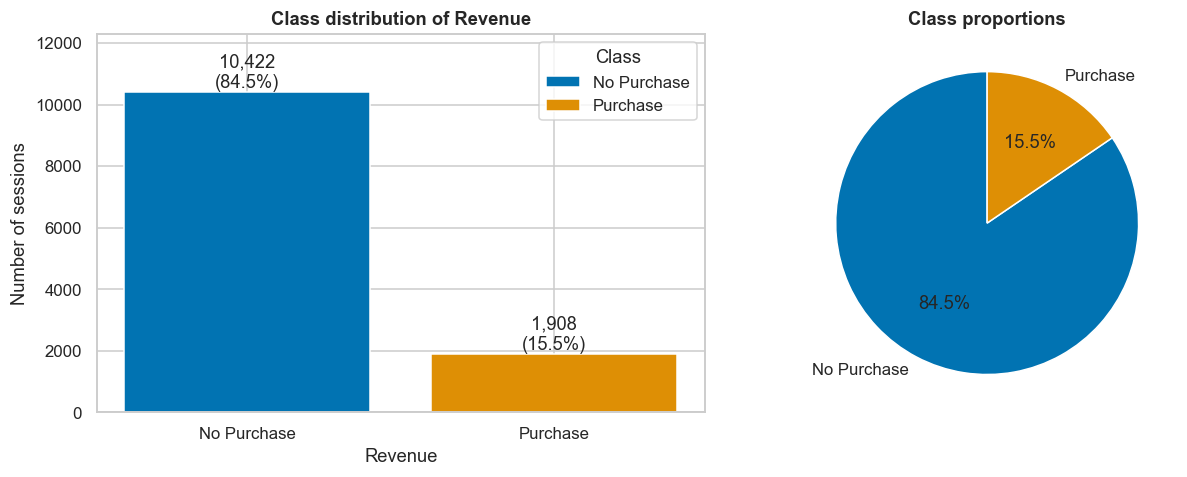

In [5]:
# Target (class) distribution
counts = df['Revenue'].value_counts().sort_index()
share = (counts / counts.sum() * 100).round(2)
display(pd.DataFrame({'count': counts, 'share_%': share}).rename(index={False: 'No Purchase', True: 'Purchase'}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(CLASS_NAMES, counts.values, color=[CLASS_COLORS[0], CLASS_COLORS[1]], label=CLASS_NAMES)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 120, f'{v:,}\n({share.values[i]:.1f}%)', ha='center')
axes[0].set(title='Class distribution of Revenue', xlabel='Revenue', ylabel='Number of sessions',
            ylim=(0, counts.max() * 1.18))
axes[0].legend(title='Class')
axes[1].pie(counts.values, labels=CLASS_NAMES, autopct='%1.1f%%', startangle=90,
            colors=[CLASS_COLORS[0], CLASS_COLORS[1]], wedgeprops={'edgecolor': 'white'})
axes[1].set_title('Class proportions')
plt.tight_layout(); save_fig(fig, 'class_distribution'); plt.show()

**📝 Observations — audit**
- 12,330 sessions × 18 columns: 10 numerical behaviour metrics, 4 integer-coded nominal fields, `Month`, `VisitorType`, `Weekend` and the target `Revenue`.
- **No missing values** in any column, so no imputation is needed. There are **125 exact duplicate rows** (handled in §3.1).
- The target is **imbalanced: 84.5 % "No Purchase" vs 15.5 % "Purchase"**. A model that always predicts "No Purchase" would already score 84.5 % accuracy, so accuracy alone is misleading. We therefore rank models by **weighted F1** and also report **ROC-AUC** and the **Purchase-class recall/F1**. The split must be **stratified** to keep the 15.5 % rate in both parts.

---
## 2 · Exploratory data analysis

`OperatingSystems`, `Browser`, `Region` and `TrafficType` are stored as integers but are **nominal codes**, so they are
analysed as categorical features.

In [6]:
TARGET = 'Revenue'
NOMINAL_CODES = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']
NUM_COLS = [c for c in df.select_dtypes('number').columns if c not in NOMINAL_CODES]
CAT_COLS = ['Month', 'VisitorType', 'Weekend'] + NOMINAL_CODES
print(f'Numerical features ({len(NUM_COLS)}): {NUM_COLS}')
print(f'Categorical features ({len(CAT_COLS)}): {CAT_COLS}')

Numerical features (10): ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Categorical features (7): ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


### 2.1 Distribution of every numerical feature

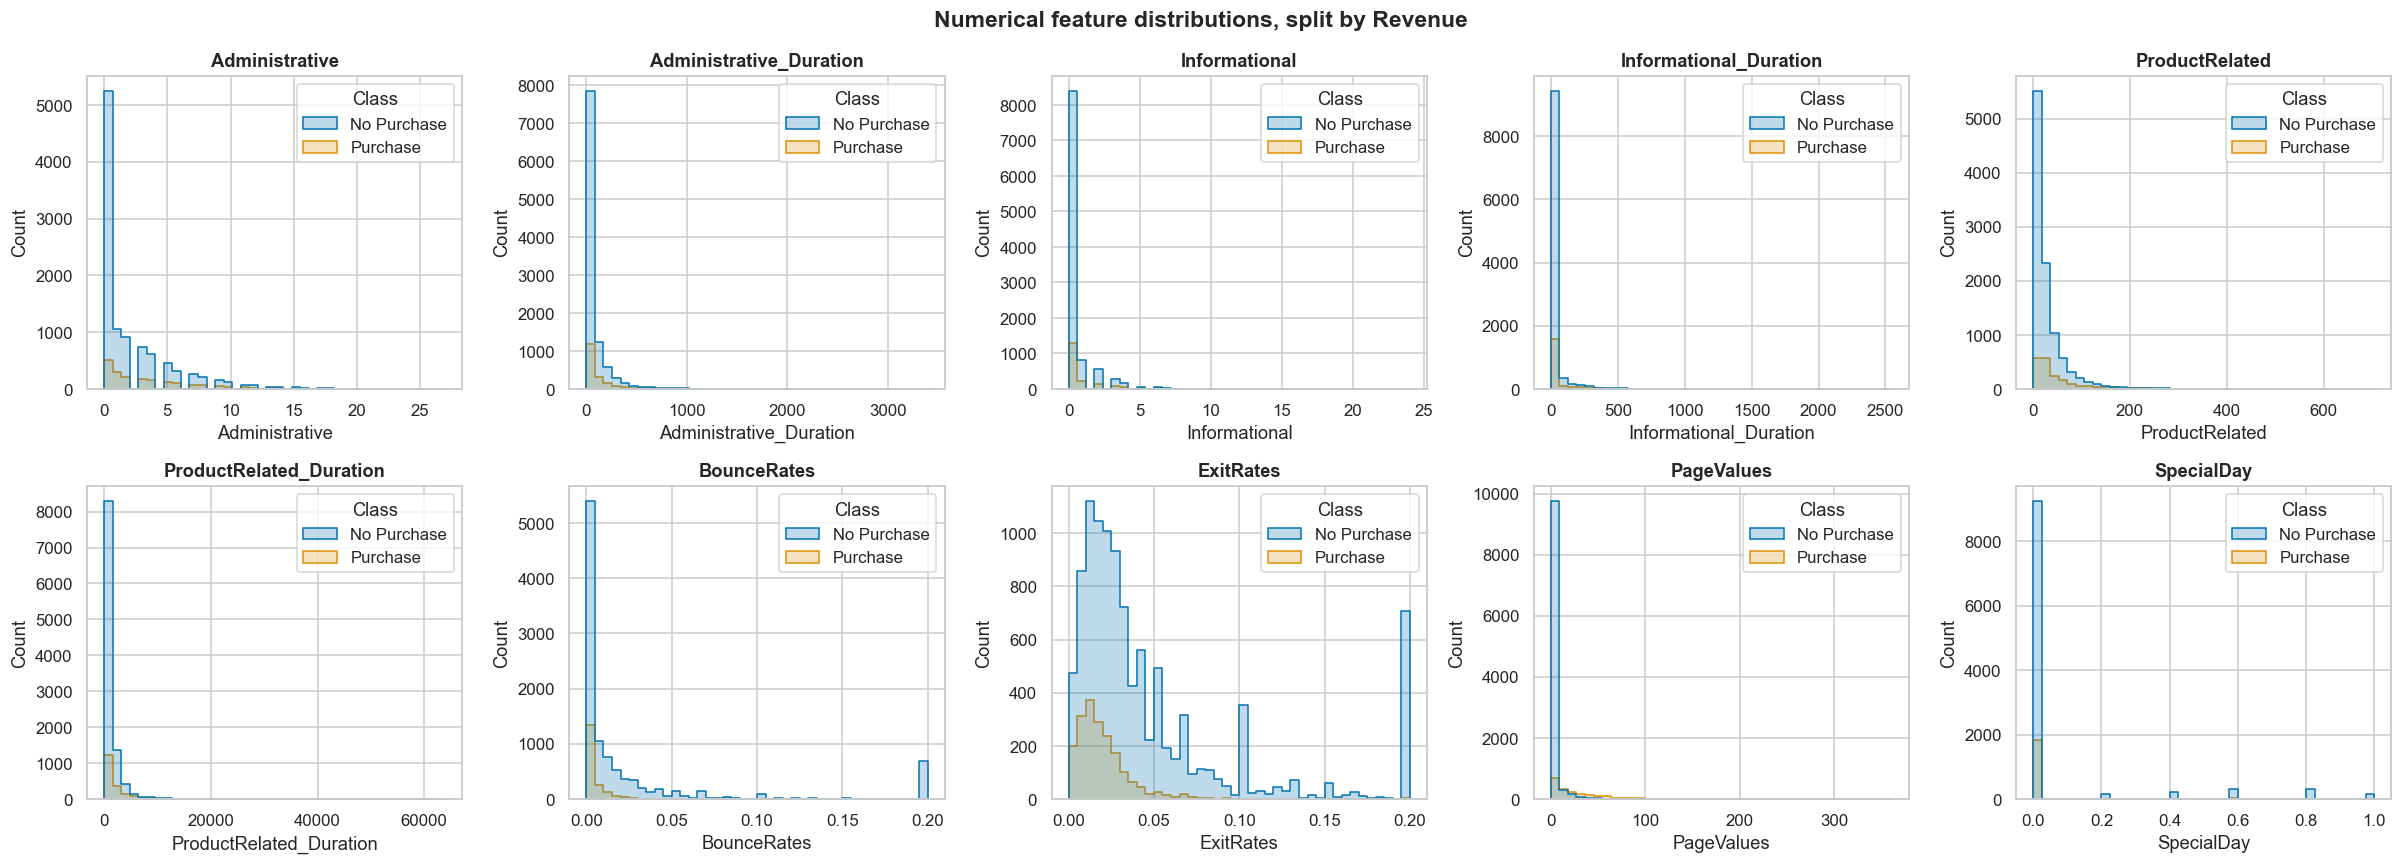

Skewness of numerical features:
Informational_Duration     7.58
ProductRelated_Duration    7.26
PageValues                 6.38
Administrative_Duration    5.62
ProductRelated             4.34
Informational              4.04
SpecialDay                 3.30
BounceRates                2.95
ExitRates                  2.15
Administrative             1.96


In [7]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
hist_df = df.assign(Class=df[TARGET].map({False: 'No Purchase', True: 'Purchase'}))
for ax, col in zip(axes.flat, NUM_COLS):
    sns.histplot(data=hist_df, x=col, hue='Class', hue_order=CLASS_NAMES, bins=40, ax=ax, element='step',
                 palette=[CLASS_COLORS[0], CLASS_COLORS[1]])
    ax.set(title=col, xlabel=col, ylabel='Count')
fig.suptitle('Numerical feature distributions, split by Revenue', fontsize=15, fontweight='bold')
plt.tight_layout(); save_fig(fig, 'numerical_distributions'); plt.show()

skew = df[NUM_COLS].skew().sort_values(ascending=False).round(2)
print('Skewness of numerical features:')
print(skew.to_string())

**📝 Observations — numerical distributions**
- Every page-count and duration feature is strongly **right-skewed** (skewness 2.0–7.6): most sessions are short, with a long tail of very long ones. This is why §3.5 applies `log1p` before scaling.
- `PageValues` is 0 for about 78 % of sessions. The purchase histogram sits clearly to the right, so this is the most separating feature.
- `BounceRates` and `ExitRates` pile up near 0 for buyers, while non-buyers have a long tail up to 0.2. High bounce/exit means the visitor leaves.
- `SpecialDay` is almost always 0. Its correlation with the target is weak and **negative** (r = −0.08): sessions close to a holiday convert slightly *less*.

### 2.2 Distribution of every categorical feature and its purchase rate

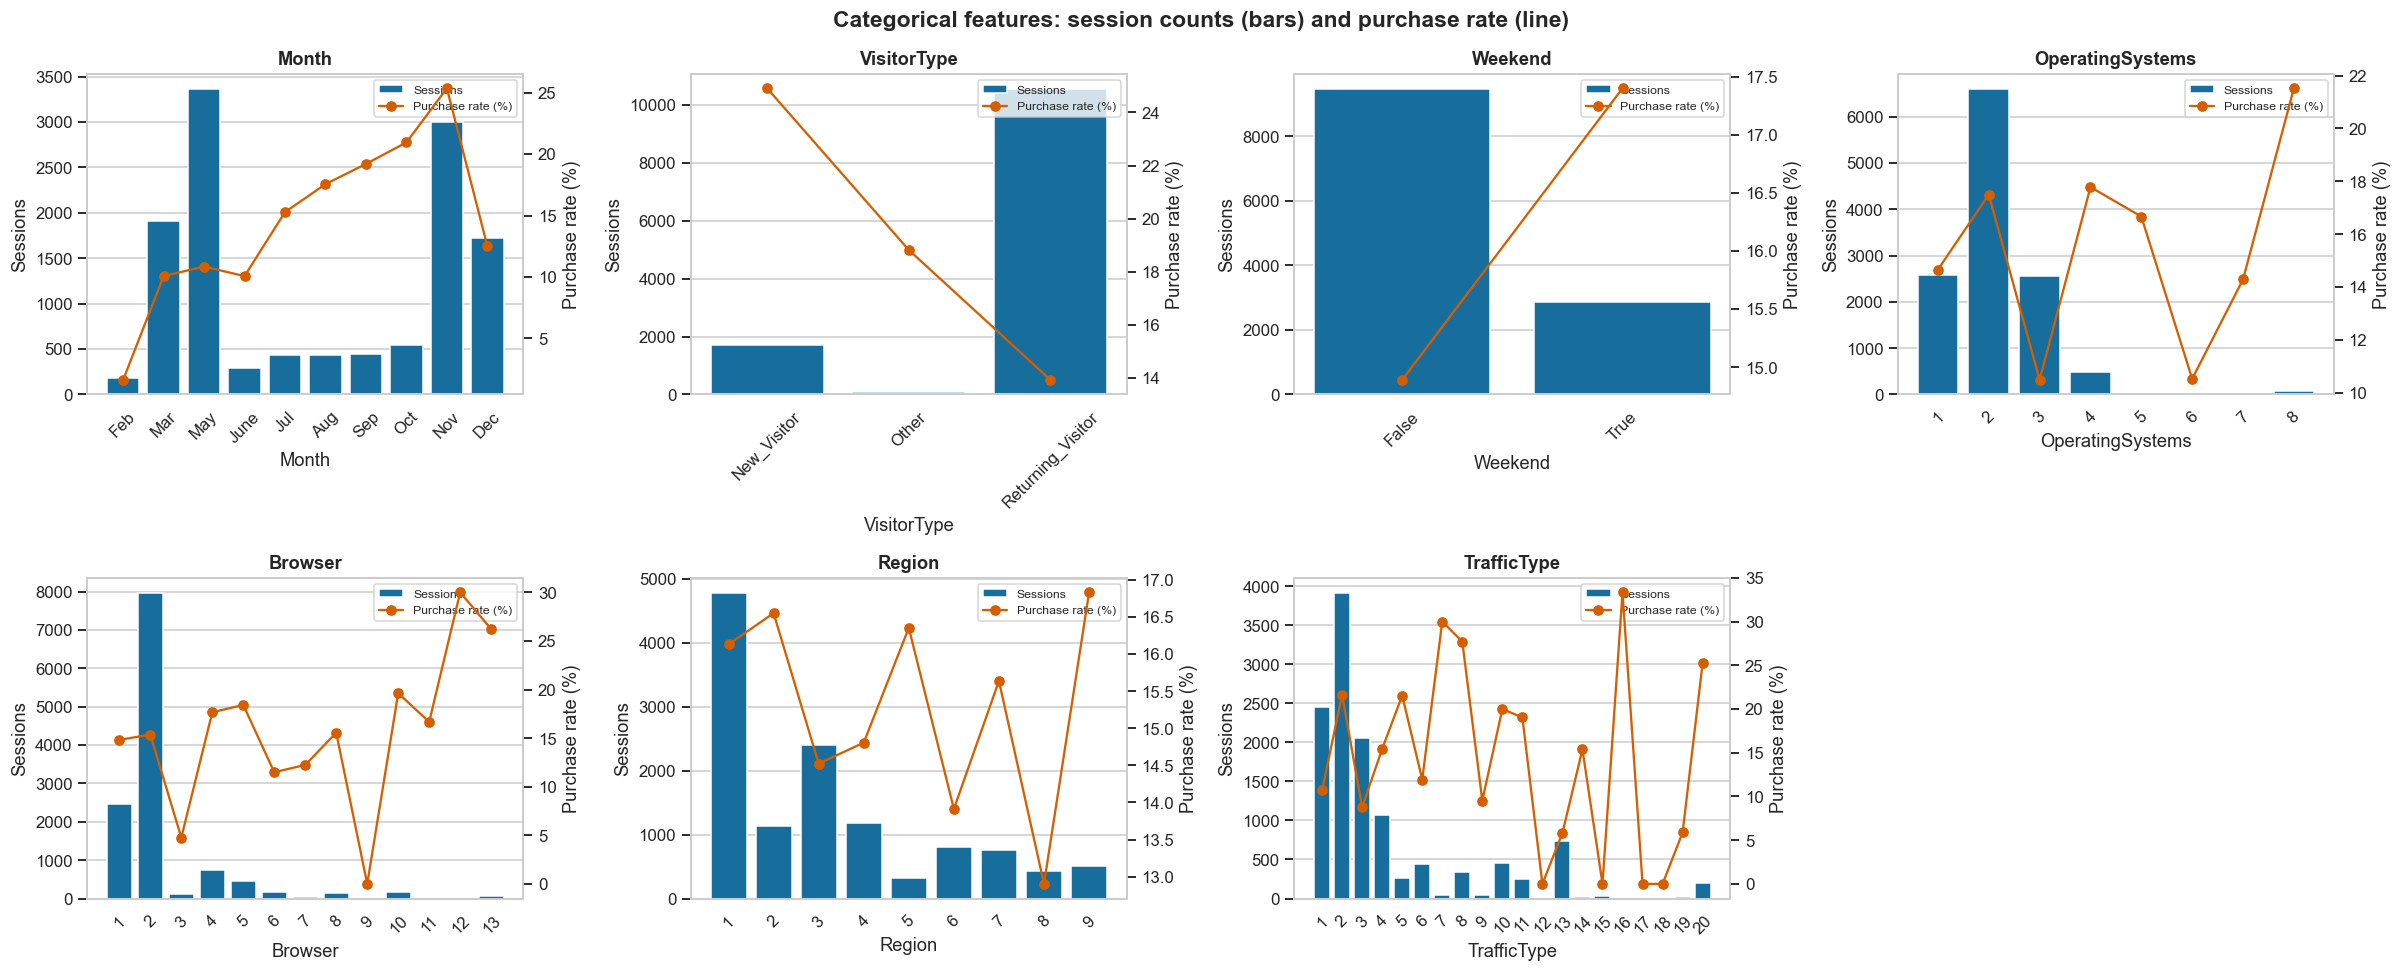

In [8]:
MONTH_ORDER = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, col in zip(axes.flat, CAT_COLS):
    order = [m for m in MONTH_ORDER if m in df[col].unique()] if col == 'Month' else sorted(df[col].unique())
    sns.countplot(data=df, x=col, order=order, ax=ax, color=PALETTE[0], label='Sessions')
    ax.set(title=col, xlabel=col, ylabel='Sessions')
    ax.tick_params(axis='x', rotation=45)
    rate = df.groupby(col)[TARGET].mean().reindex(order) * 100
    ax2 = ax.twinx()
    ax2.plot(range(len(order)), rate.values, color=PALETTE[3], marker='o', label='Purchase rate (%)')
    ax2.set_ylabel('Purchase rate (%)'); ax2.grid(False)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper right')
axes.flat[-1].set_visible(False)
fig.suptitle('Categorical features: session counts (bars) and purchase rate (line)', fontsize=15, fontweight='bold')
plt.tight_layout(); save_fig(fig, 'categorical_distributions'); plt.show()

**📝 Observations — categorical distributions**
- **Month:** traffic peaks in May and November, but the **conversion rate peaks in November (~25 %)** and is lowest in February (~1.6 %). Seasonality matters, so `Month` is kept and encoded in calendar order. January and April are absent from the data.
- **VisitorType:** returning visitors are 85 % of traffic but convert *less* (~14 %) than new visitors (~25 %). This is a useful, non-obvious signal.
- **Weekend:** weekend sessions convert slightly more (~17.4 % vs ~14.9 %).
- **OperatingSystems / Browser / Region / TrafficType:** a few codes dominate and many codes have only a handful of sessions, with purchase rates that jump around. These are **identifiers, not quantities**, so they are one-hot encoded with rare codes grouped (§3.5).

### 2.3 Correlation heatmap

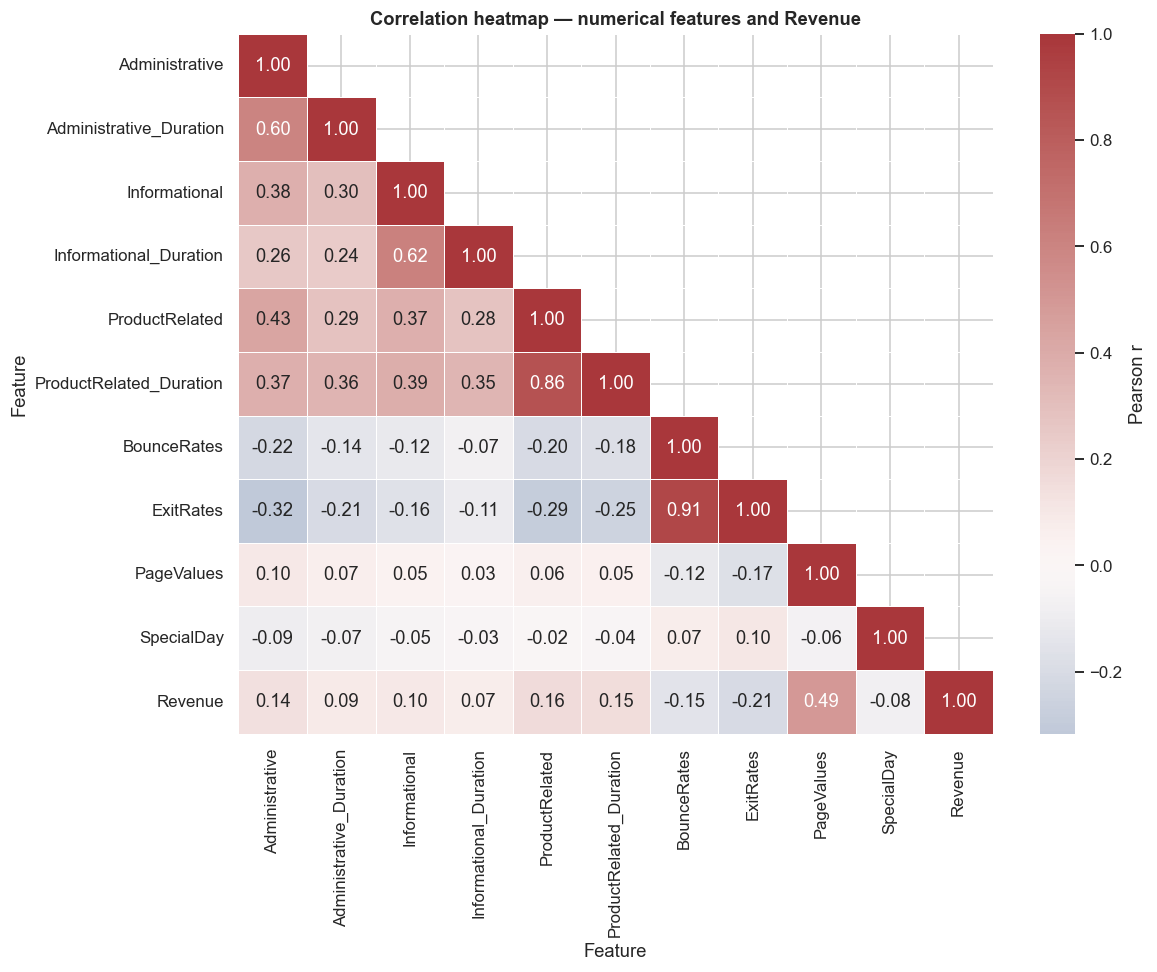

Correlation with Revenue (sorted):
PageValues                 0.493
ProductRelated             0.159
ProductRelated_Duration    0.152
Administrative             0.139
Informational              0.095
Administrative_Duration    0.094
Informational_Duration     0.070
SpecialDay                -0.082
BounceRates               -0.151
ExitRates                 -0.207


In [9]:
corr = df[NUM_COLS + [TARGET]].assign(Revenue=df[TARGET].astype(int)).corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt='.2f',
            cmap='vlag', center=0, linewidths=0.5, cbar_kws={'label': 'Pearson r'}, ax=ax)
ax.set(title='Correlation heatmap — numerical features and Revenue', xlabel='Feature', ylabel='Feature')
plt.tight_layout(); save_fig(fig, 'correlation_heatmap'); plt.show()

print('Correlation with Revenue (sorted):')
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

**📝 Observations — correlation heatmap**
- `PageValues` has by far the strongest linear correlation with `Revenue` (**r = 0.49**). Next come `ExitRates` (−0.21), `ProductRelated` (0.16), `ProductRelated_Duration` (0.15) and `BounceRates` (−0.15).
- There is strong **multicollinearity**: `BounceRates`↔`ExitRates` (r ≈ 0.91), `ProductRelated`↔`ProductRelated_Duration` (≈ 0.86), and every page count with its own duration. Linear models and Naive Bayes are sensitive to this; tree ensembles are not.
- Apart from `PageValues`, all correlations are weak (|r| ≤ 0.21). This suggests the relationship is **non-linear and interaction-driven**, which favours tree ensembles.

### 2.4 Feature distributions by class (box plots, log scale)

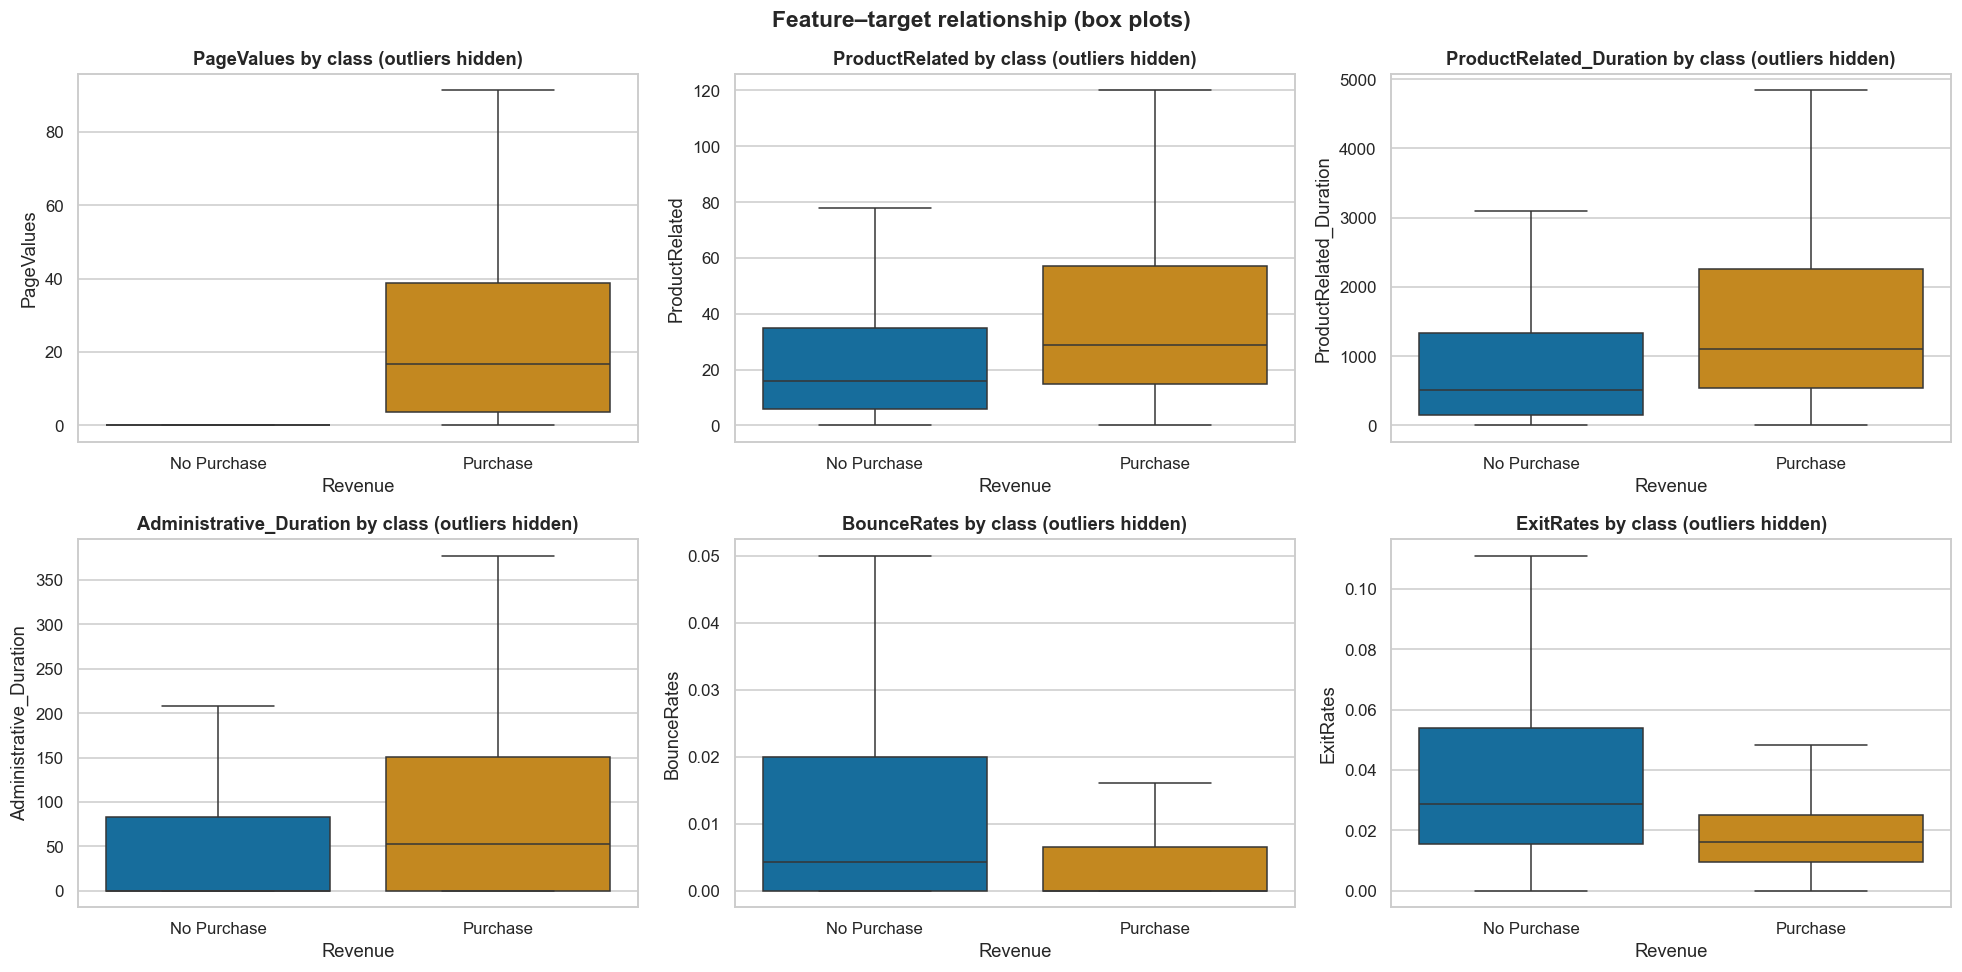

,PageValues,ProductRelated,ProductRelated_Duration,Administrative_Duration,BounceRates,ExitRates
Revenue,,,,,,
No Purchase (median),0.000,16.0,510.190,0.000,0.004,0.029
Purchase (median),16.758,29.0,1109.906,52.367,0.000,0.016


In [10]:
key_feats = ['PageValues', 'ProductRelated', 'ProductRelated_Duration',
             'Administrative_Duration', 'BounceRates', 'ExitRates']
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
plot_df = df.assign(Class=df[TARGET].map({False: 'No Purchase', True: 'Purchase'}))
for ax, col in zip(axes.flat, key_feats):
    sns.boxplot(data=plot_df, x='Class', y=col, hue='Class', order=CLASS_NAMES,
                palette=[CLASS_COLORS[0], CLASS_COLORS[1]], ax=ax, legend=False, showfliers=False)
    ax.set(title=f'{col} by class (outliers hidden)', xlabel='Revenue', ylabel=col)
fig.suptitle('Feature–target relationship (box plots)', fontsize=15, fontweight='bold')
plt.tight_layout(); save_fig(fig, 'boxplots_by_class'); plt.show()

display(df.groupby(TARGET)[key_feats].median().rename(index={False: 'No Purchase (median)', True: 'Purchase (median)'}).round(3))

**📝 Observations — box plots by class**
- Median `PageValues` is **0 for non-buyers vs 16.8 for buyers**, the clearest separation of any feature.
- Buyers view more product pages (median 29 vs 16) and spend about twice as long on them (median 1,110 s vs 510 s).
- Buyers have **lower bounce and exit rates** (median exit rate 0.016 vs 0.029). Visitors who leave quickly rarely buy.

### 2.5 Feature–target scatter plots (with empirical purchase probability)

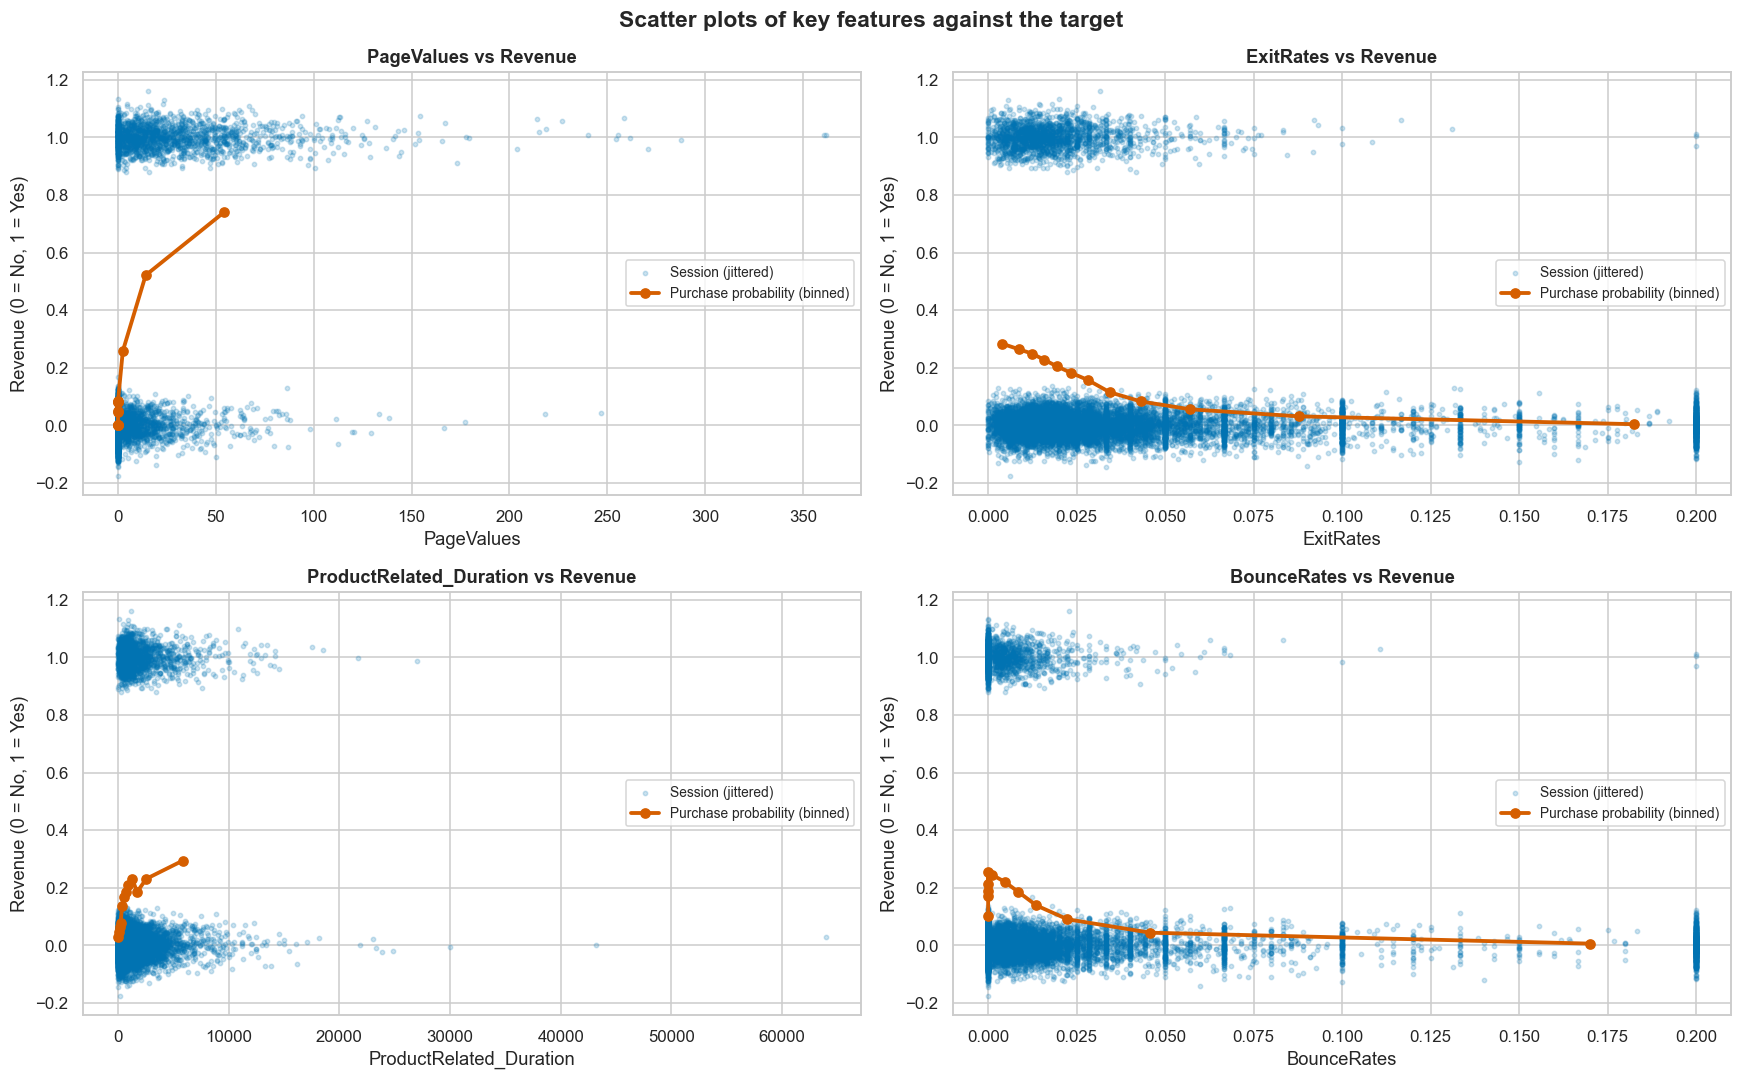

In [11]:
rng = np.random.default_rng(RANDOM_STATE)
jitter = rng.normal(0, 0.04, len(df))
y_num = df[TARGET].astype(int)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, feat in zip(axes.flat, ['PageValues', 'ExitRates', 'ProductRelated_Duration', 'BounceRates']):
    ax.scatter(df[feat], y_num + jitter, s=8, alpha=0.2, color=PALETTE[0], label='Session (jittered)')
    bins = pd.qcut(df[feat].rank(method='first'), q=12)
    trend = df.groupby(bins, observed=True).agg(x=(feat, 'mean'), p=(TARGET, 'mean'))
    ax.plot(trend['x'], trend['p'], color=PALETTE[3], marker='o', lw=2.5, label='Purchase probability (binned)')
    ax.set(title=f'{feat} vs Revenue', xlabel=feat, ylabel='Revenue (0 = No, 1 = Yes)')
    ax.legend(fontsize=9, loc='center right')
fig.suptitle('Scatter plots of key features against the target', fontsize=15, fontweight='bold')
plt.tight_layout(); save_fig(fig, 'feature_target_scatter'); plt.show()

**📝 Observations — feature–target scatter plots**
- **PageValues:** the binned purchase probability is very low while `PageValues = 0` and jumps above 50 % once it is positive. The relationship is a **threshold/step** rather than a straight line.
- **ExitRates and BounceRates:** purchase probability falls steeply as these rates rise and is close to 0 for the highest bins. This is a clear negative relationship.
- **ProductRelated_Duration:** purchase probability rises steadily with time spent on product pages.
- These shapes motivated two engineered features: `HasPageValue` (captures the step) and `AvgProductPageTime` (reading depth).

---
## 3 · Cleaning, feature engineering, encoding & splitting

> **Data-leakage rule (guideline 7.1):** every learned transformation (scaler, encoders) lives inside a
> `ColumnTransformer` that is **fitted on the training split only** and then applied to the test split.

### 3.1 Missing values and duplicates

In [12]:
data = df.copy()
print(f'Missing values: {int(data.isna().sum().sum())} → no imputation required')

n_dup = int(data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)
print(f'Removed {n_dup} exact duplicate sessions → {len(data):,} rows remain')
print(f'Purchase rate after de-duplication: {data[TARGET].mean():.2%}')

Missing values: 0 → no imputation required
Removed 125 exact duplicate sessions → 12,205 rows remain
Purchase rate after de-duplication: 15.63%


**📝 Observation — duplicates.** 125 identical rows (one-page sessions with near-identical values) were removed. Without this, the same session could end up in both train and test and inflate the test score. The purchase rate barely changes (15.47 % → 15.63 %).

### 3.2 Outlier check

In [13]:
def iqr_outlier_report(frame, cols, k=3.0):
    """Count values outside [Q1 - k·IQR, Q3 + k·IQR] for each column."""
    rows = []
    for c in cols:
        q1, q3 = frame[c].quantile([0.25, 0.75])
        lo, hi = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
        n = int(((frame[c] < lo) | (frame[c] > hi)).sum())
        rows.append({'feature': c, 'lower': round(lo, 2), 'upper': round(hi, 2),
                     'outliers': n, 'outliers_%': round(100 * n / len(frame), 2),
                     'purchase_rate_in_outliers_%': round(100 * frame.loc[(frame[c] < lo) | (frame[c] > hi), TARGET].mean(), 1) if n else np.nan})
    return pd.DataFrame(rows).set_index('feature')

display(iqr_outlier_report(data, NUM_COLS))

,lower,upper,outliers,outliers_%,purchase_rate_in_outliers_%
feature,,,,,
Administrative,-12.00,16.00,51,0.42,21.6
Administrative_Duration,-284.10,378.80,540,4.42,26.3
Informational,0.00,0.00,2631,21.56,23.3
Informational_Duration,0.00,0.00,2405,19.71,23.5
ProductRelated,-82.00,128.00,446,3.65,34.1
ProductRelated_Duration,-3659.46,5329.62,398,3.26,33.9
BounceRates,-0.05,0.07,924,7.57,0.8
ExitRates,-0.09,0.15,666,5.46,0.5
PageValues,0.00,0.00,2730,22.37,56.3


**📝 Observations — outliers (3×IQR rule)**
- Many values are flagged. For `PageValues`, `Informational` and `SpecialDay`, the IQR is 0, so *every* non-zero value counts as an "outlier".
- These "outliers" are **highly informative**. Sessions flagged on `PageValues` convert at **56 %** and those flagged on `ProductRelated` at 34 %, against 15.6 % overall. Those flagged on `ExitRates`/`BounceRates` convert at **under 1 %**.
- **Decision:** keep every row. Deleting or capping would throw away the strongest signals. The `log1p` transform in §3.5 compresses the long tails so that LR, KNN, SVC and the MLP are not dominated by a few extreme sessions, and tree models are unaffected by monotone transforms.

### 3.3 Feature engineering

| New feature | Definition | Why it may help |
|-------------|-----------|-----------------|
| `TotalPageVisits` | Administrative + Informational + ProductRelated | overall breadth of engagement in the session |
| `TotalDuration` | sum of the three duration columns | total time on site = depth of the session |
| `ProductEngagementRatio` | ProductRelated_Duration / TotalDuration | share of time spent on product pages (shopping focus) |
| `AvgProductPageTime` | ProductRelated_Duration / ProductRelated | how carefully each product page is read |
| `HasPageValue` | 1 if PageValues > 0 | a non-zero page value means the visitor reached pages that precede a transaction |

In [14]:
def engineer_features(frame):
    """Add the five engineered session features (pure row-wise maths → no leakage)."""
    out = frame.copy()
    out['TotalPageVisits'] = out['Administrative'] + out['Informational'] + out['ProductRelated']
    out['TotalDuration'] = (out['Administrative_Duration'] + out['Informational_Duration']
                            + out['ProductRelated_Duration'])
    out['ProductEngagementRatio'] = np.where(out['TotalDuration'] > 0,
                                             out['ProductRelated_Duration'] / out['TotalDuration'], 0.0)
    out['AvgProductPageTime'] = np.where(out['ProductRelated'] > 0,
                                         out['ProductRelated_Duration'] / out['ProductRelated'], 0.0)
    out['HasPageValue'] = (out['PageValues'] > 0).astype(int)
    out['Weekend'] = out['Weekend'].astype(int)
    return out

data = engineer_features(data)
ENGINEERED = ['TotalPageVisits', 'TotalDuration', 'ProductEngagementRatio', 'AvgProductPageTime', 'HasPageValue']
display(data[ENGINEERED].describe().T.round(3))

# Quick evidence that the engineered features carry signal
signal = pd.DataFrame({
    'corr_with_Revenue': data[ENGINEERED].corrwith(data[TARGET].astype(int)).round(3),
})
display(signal)
print('Purchase rate by HasPageValue:')
print((data.groupby('HasPageValue')[TARGET].mean() * 100).round(2).rename('purchase_rate_%').to_string())

,count,mean,std,min,25%,50%,75%,max
TotalPageVisits,12205.0,34.893,46.627,0.0,9.000,20.000,42.000,746.000
TotalDuration,12205.0,1323.454,2043.872,0.0,231.667,690.958,1643.958,69921.647
ProductEngagementRatio,12205.0,0.851,0.256,0.0,0.831,0.969,1.000,1.000
AvgProductPageTime,12205.0,38.019,44.833,0.0,17.979,29.146,45.292,1411.000
HasPageValue,12205.0,0.224,0.417,0.0,0.000,0.000,0.000,1.000


,corr_with_Revenue
TotalPageVisits,0.162
TotalDuration,0.154
ProductEngagementRatio,0.057
AvgProductPageTime,0.038
HasPageValue,0.602


Purchase rate by HasPageValue:
HasPageValue
0     3.91
1    56.34


**📝 Observations — engineered features**
- **`HasPageValue` is the most correlated single feature in the dataset (r = 0.60 with Revenue, vs 0.49 for raw `PageValues`).** Sessions with a page value convert at **56.3 %**, sessions without one at **3.9 %**. It turns the step-shaped relationship from §2.5 into a direct binary signal that linear models can use.
- `TotalPageVisits` (r = 0.16) and `TotalDuration` (r = 0.15) summarise engagement in one number each, and are slightly stronger than any single page-type count.
- `ProductEngagementRatio` and `AvgProductPageTime` have weak *linear* correlation (0.06, 0.04). They describe *how* the visitor browses (shopping focus, reading depth), which tree models can combine with other features.
- All five features use only values from the same row, so creating them before the split cannot leak information between train and test.

### 3.4 Stratified train / test split (80 : 20)

In [15]:
X = data.drop(columns=[TARGET])
y = data[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

split_info = pd.DataFrame({
    'rows': [len(X_train), len(X_test)],
    'purchase_rate_%': [y_train.mean() * 100, y_test.mean() * 100],
}, index=['train', 'test']).round(2)
display(split_info)

,rows,purchase_rate_%
train,9764,15.63
test,2441,15.65


### 3.5 Encoding & scaling with a leak-free `ColumnTransformer`

In [16]:
LOG_SCALE = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
             'ProductRelated', 'ProductRelated_Duration', 'PageValues',
             'TotalPageVisits', 'TotalDuration', 'AvgProductPageTime']        # heavily right-skewed
SCALE = ['BounceRates', 'ExitRates', 'SpecialDay', 'ProductEngagementRatio']  # bounded in [0, 1]
ORDINAL = ['Month']                                                            # calendar order
NOMINAL = ['VisitorType'] + NOMINAL_CODES                                      # no natural order
BINARY = ['Weekend', 'HasPageValue']                                           # already 0/1


def build_preprocessor():
    """Unfitted preprocessing transformer — fitted later on the training data only."""
    return ColumnTransformer([
        ('log_num', make_pipeline(FunctionTransformer(np.log1p, feature_names_out='one-to-one'),
                                  StandardScaler()), LOG_SCALE),
        ('num', StandardScaler(), SCALE),
        ('month', make_pipeline(OrdinalEncoder(categories=[MONTH_ORDER], handle_unknown='use_encoded_value',
                                               unknown_value=-1), StandardScaler()), ORDINAL),
        ('nominal', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50,
                                  sparse_output=False), NOMINAL),
        ('binary', 'passthrough', BINARY),
    ], verbose_feature_names_out=False).set_output(transform='pandas')


preprocessor = build_preprocessor().fit(X_train)          # <-- fitted on TRAIN only
X_train_p = preprocessor.transform(X_train)
X_test_p = preprocessor.transform(X_test)                  # <-- test only transformed

print(f'Raw feature columns       : {X_train.shape[1]}')
print(f'Model-ready feature columns: {X_train_p.shape[1]}')
print(f'Train matrix: {X_train_p.shape} | Test matrix: {X_test_p.shape}')
print('Train means of scaled columns ≈ 0:', X_train_p[LOG_SCALE + SCALE].mean().abs().max().round(6))
display(X_train_p.head(3))

Raw feature columns       : 22
Model-ready feature columns: 57
Train matrix: (9764, 57) | Test matrix: (2441, 57)


Train means of scaled columns ≈ 0: 0.0


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,PageValues,TotalPageVisits,TotalDuration,AvgProductPageTime,BounceRates,ExitRates,SpecialDay,ProductEngagementRatio,Month,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor,OperatingSystems_1,OperatingSystems_2,...,Region_4,Region_5,Region_6,Region_7,Region_8,Region_9,TrafficType_1,TrafficType_2,TrafficType_3,TrafficType_4,TrafficType_5,TrafficType_6,TrafficType_8,TrafficType_10,TrafficType_11,TrafficType_13,TrafficType_20,TrafficType_infrequent_sklearn,Weekend,HasPageValue
7469,1.611141,1.262702,0.910139,-0.466446,0.768974,0.475422,2.376241,0.854493,0.501785,-0.017600,-0.448703,-0.800192,-0.311837,-0.053737,0.990316,0.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1
11804,-0.931857,-0.984421,-0.481472,-0.466446,0.474491,0.396448,2.307451,0.384384,0.330534,0.153377,-0.448703,-0.739774,-0.311837,0.580153,1.285702,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1
3250,-0.931857,-0.984421,-0.481472,-0.466446,-0.240924,0.009070,-0.495351,-0.338090,-0.061781,0.224770,-0.448703,-0.287446,3.689185,0.580153,-0.781997,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0


**Preprocessing summary**

| Step | Strategy | Justification |
|------|----------|---------------|
| Missing values | none present | audit in §1 confirmed 0 missing values |
| Duplicates | 125 exact duplicates removed | identical sessions would leak between train and test and inflate scores |
| Outliers | retained, compressed with `log1p` | extreme sessions are genuine and highly informative (§3.2) |
| Feature engineering | 5 new features | §3.3 |
| `Month` | ordinal (calendar order) + scaled | preserves seasonality order |
| `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType` | one-hot, levels with < 50 training rows grouped as *infrequent* | nominal codes; grouping avoids dozens of near-empty columns |
| Skewed counts / durations | `log1p` → `StandardScaler` | distance- and gradient-based models need comparable scales |
| Split | stratified 80:20, `random_state=42` | keeps the 15.5 % purchase rate in both splits |
| Leakage control | transformer fitted on `X_train` only | guideline 7.1 |

All **10 models** below use exactly the same `X_train_p / X_test_p` matrices, so their scores are directly comparable.

---
## 4 · Modelling framework

* **`evaluate()`** computes every mandatory metric on the common test split — Accuracy, weighted Precision, weighted
  Recall, weighted F1, ROC-AUC and the confusion matrix — plus the *Purchase-class* recall/F1, which matter most to the
  business.
* **`tune()`** runs `GridSearchCV` with **5-fold stratified CV on the training split only** (scoring = weighted F1).
* For every algorithm we first fit a **baseline** (library defaults) and then the **tuned** model, so the improvement from
  tuning is always documented.

In [17]:
RESULTS = {}      # (model name, stage) -> metrics + fitted model + predictions
SEARCHES = {}     # model name -> fitted GridSearchCV object


def scores_for_auc(model, X):
    """Probability of the positive class, or the decision score when probabilities are unavailable (SVC)."""
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def evaluate(name, model, stage, part, X_te=None, y_te=None):
    """Evaluate a FITTED model on the common test split and store the results."""
    X_te = X_test_p if X_te is None else X_te
    y_te = y_test if y_te is None else y_te
    y_pred = model.predict(X_te)
    y_score = scores_for_auc(model, X_te)
    row = {
        'Model': name, 'Part': part, 'Stage': stage,
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision (w)': precision_score(y_te, y_pred, average='weighted', zero_division=0),
        'Recall (w)': recall_score(y_te, y_pred, average='weighted'),
        'F1 (w)': f1_score(y_te, y_pred, average='weighted'),
        'ROC-AUC': roc_auc_score(y_te, y_score),
        'Purchase Recall': recall_score(y_te, y_pred, pos_label=1),
        'Purchase F1': f1_score(y_te, y_pred, pos_label=1),
    }
    RESULTS[(name, stage)] = {**row, 'model': model, 'y_pred': y_pred, 'y_score': y_score,
                              'cm': confusion_matrix(y_te, y_pred)}
    return row


def tune(name, estimator, grid):
    """GridSearchCV with 5-fold stratified CV on the training split (scoring = weighted F1)."""
    t0 = time.time()
    search = GridSearchCV(estimator, grid, scoring='f1_weighted', cv=CV5, n_jobs=-1)
    search.fit(X_train_p, y_train)
    SEARCHES[name] = search
    print(f'{name}: {len(search.cv_results_["params"])} candidates × 5 folds in {time.time() - t0:.1f}s')
    print(f'  best params : {fmt_params(search.best_params_)}')
    print(f'  best CV F1  : {search.best_score_:.4f}')
    return search.best_estimator_


def run_model(name, part, baseline, grid):
    """Fit the baseline, tune with GridSearchCV, evaluate both and show a before/after table."""
    base = clone(baseline).fit(X_train_p, y_train)
    rows = [evaluate(name, base, 'Baseline', part)]
    best = tune(name, clone(baseline), grid)
    rows.append(evaluate(name, best, 'Tuned', part))
    table = pd.DataFrame(rows).set_index('Stage').drop(columns=['Model', 'Part'])
    display(table.style.format('{:.4f}').set_caption(f'{name} — baseline vs tuned (test split)'))
    return base, best


def cv_curve(name, param, fixed=None):
    """Mean ± std CV score along one hyper-parameter, other params fixed at their best values."""
    res = pd.DataFrame(SEARCHES[name].cv_results_)
    best = SEARCHES[name].best_params_
    fixed = {k: v for k, v in best.items() if k != param} if fixed is None else fixed
    mask = np.ones(len(res), dtype=bool)
    for k, v in fixed.items():
        mask &= res[f'param_{k}'].astype(str) == str(v)
    return res.loc[mask, [f'param_{param}', 'mean_test_score', 'std_test_score']].rename(
        columns={f'param_{param}': param})


def fmt_params(params, prefix=''):
    """Readable hyper-parameter dict: plain Python numbers, optional key prefix removed."""
    return {k.replace(prefix, ''): (float(f'{v:.4g}') if isinstance(v, (float, np.floating)) else v)
            for k, v in params.items()}


print('Helpers ready: evaluate(), tune(), run_model(), cv_curve(), fmt_params()')

Helpers ready: evaluate(), tune(), run_model(), cv_curve(), fmt_params()


---
## 5 · Part A classifiers (Review 1 scope, re-run with CV-based tuning)

### 5.1 Logistic Regression — baseline classifier; interpret coefficients / odds ratios
Models the log-odds of a purchase as a linear function of the features. Tuned hyper-parameter: inverse regularisation
strength `C`.

In [18]:
lr_base, lr_best = run_model(
    'Logistic Regression', 'A',
    LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    {'C': [0.001, 0.01, 0.1, 1, 10, 100]})

Logistic Regression: 6 candidates × 5 folds in 4.7s
  best params : {'C': 1}
  best CV F1  : 0.8877


,Accuracy,Precision (w),Recall (w),F1 (w),ROC-AUC,Purchase Recall,Purchase F1
Stage,,,,,,,
Baseline,0.8955,0.8914,0.8955,0.8931,0.9174,0.6126,0.6473
Tuned,0.8955,0.8914,0.8955,0.8931,0.9174,0.6126,0.6473


,coefficient,odds_ratio
HasPageValue,2.021,7.547
TotalPageVisits,1.055,2.871
ProductRelated,-0.918,0.399
Browser_3,-0.823,0.439
TotalDuration,0.743,2.102
PageValues,0.708,2.031
TrafficType_13,-0.630,0.532
VisitorType_Returning_Visitor,-0.606,0.546
Browser_6,-0.597,0.550
ProductRelated_Duration,-0.590,0.554


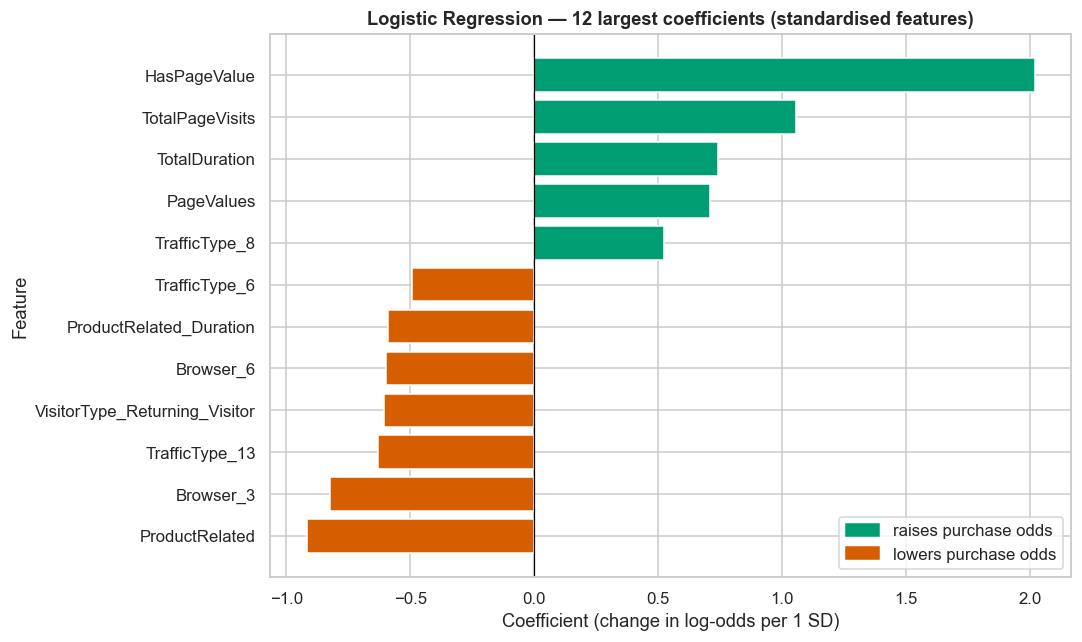

In [19]:
coef = pd.Series(lr_best.coef_[0], index=X_train_p.columns)
odds = pd.DataFrame({'coefficient': coef, 'odds_ratio': np.exp(coef)})
top = odds.reindex(coef.abs().sort_values(ascending=False).index).head(12)
display(top.round(3))

fig, ax = plt.subplots(figsize=(10, 6))
plot_top = top.sort_values('coefficient')
ax.barh(plot_top.index, plot_top['coefficient'],
        color=[PALETTE[2] if v > 0 else PALETTE[3] for v in plot_top['coefficient']])
ax.axvline(0, color='black', lw=0.8)
ax.set(title='Logistic Regression — 12 largest coefficients (standardised features)',
       xlabel='Coefficient (change in log-odds per 1 SD)', ylabel='Feature')
ax.legend(handles=[Patch(color=PALETTE[2], label='raises purchase odds'),
                   Patch(color=PALETTE[3], label='lowers purchase odds')], loc='lower right')
plt.tight_layout(); save_fig(fig, 'lr_coefficients'); plt.show()

**📝 Observations — Logistic Regression**
- The CV search selected **C = 1** (the default), so the baseline and tuned models are identical: test **weighted F1 = 0.8931, ROC-AUC = 0.9174**. Stronger regularisation (small C) under-fits, and weaker regularisation gives no gain.
- **Odds-ratio interpretation:** with every other feature held fixed, a session with a non-zero page value has **7.5× higher odds** of purchase (`HasPageValue`, OR = 7.55). One standard deviation more total pages multiplies the odds by 2.9, and more total time by 2.1.
- Some coefficients are negative even though the raw correlation is positive (e.g. `ProductRelated`, OR = 0.40). This happens because `ProductRelated`, `TotalPageVisits` and the durations are almost collinear (r ≈ 0.99), so the model splits their joint effect between them. **Coefficients of correlated features should not be read in isolation.**
- Returning visitors have lower odds than new visitors (OR = 0.55), which matches the EDA.

### 5.2 K-Nearest Neighbours — tune `k`; discuss distance metrics
A session is labelled by the majority vote of its `k` closest training sessions. We search `k`, the distance metric
(Euclidean vs Manhattan) and the vote weighting.

In [20]:
knn_base, knn_best = run_model(
    'K-Nearest Neighbours', 'A',
    KNeighborsClassifier(),
    {'n_neighbors': list(range(1, 32, 2)), 'metric': ['euclidean', 'manhattan'],
     'weights': ['uniform', 'distance']})

K-Nearest Neighbours: 64 candidates × 5 folds in 12.9s
  best params : {'metric': 'euclidean', 'n_neighbors': 17, 'weights': 'uniform'}
  best CV F1  : 0.8872


,Accuracy,Precision (w),Recall (w),F1 (w),ROC-AUC,Purchase Recall,Purchase F1
Stage,,,,,,,
Baseline,0.8910,0.8849,0.8910,0.8870,0.8666,0.5707,0.6211
Tuned,0.8890,0.8806,0.8890,0.8827,0.8986,0.5262,0.5973


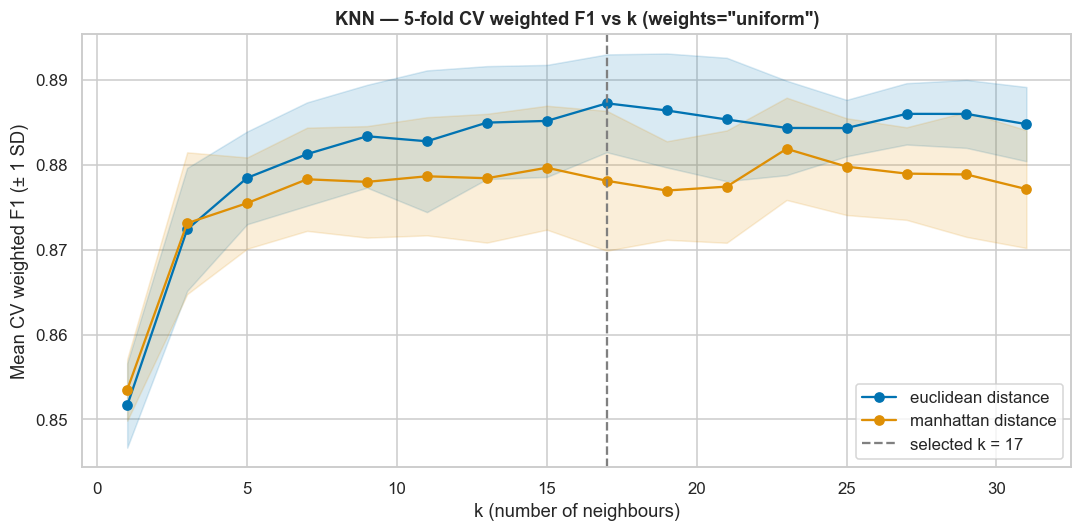

In [21]:
best_w = SEARCHES['K-Nearest Neighbours'].best_params_['weights']
fig, ax = plt.subplots(figsize=(10, 5))
for metric, color in zip(['euclidean', 'manhattan'], [PALETTE[0], PALETTE[1]]):
    c = cv_curve('K-Nearest Neighbours', 'n_neighbors', {'metric': metric, 'weights': best_w})
    k = c['n_neighbors'].astype(int)
    ax.plot(k, c['mean_test_score'], marker='o', color=color, label=f'{metric} distance')
    ax.fill_between(k, c['mean_test_score'] - c['std_test_score'], c['mean_test_score'] + c['std_test_score'],
                    color=color, alpha=0.15)
best_k = SEARCHES['K-Nearest Neighbours'].best_params_['n_neighbors']
ax.axvline(best_k, ls='--', color='grey', label=f'selected k = {best_k}')
ax.set(title=f'KNN — 5-fold CV weighted F1 vs k (weights="{best_w}")', xlabel='k (number of neighbours)',
       ylabel='Mean CV weighted F1 (± 1 SD)')
ax.legend()
plt.tight_layout(); save_fig(fig, 'knn_k_curve'); plt.show()

**📝 Observations — K-Nearest Neighbours**
- CV selected **k = 17, Euclidean distance, uniform weights** (CV F1 0.8872). Very small k over-fits to noisy neighbours, which the left side of the curve shows clearly.
- **Distance metrics:** Euclidean distance is the straight-line distance, so a large difference in one feature dominates. Manhattan distance sums absolute differences and is more robust to single extreme coordinates. After the log + standard scaling the two curves are close, with Euclidean slightly ahead.
- On the test split the tuned model's weighted F1 (0.8827) is slightly *below* the k = 5 default (0.8870), but its **ROC-AUC rises from 0.867 to 0.899**. Averaging 17 neighbours gives smoother probabilities and a better *ranking* of sessions. A 0.004 F1 difference on one split is within CV noise, and we keep the CV choice because it is the unbiased selection rule.
- KNN ranks second-to-last: with 57 dimensions, many of them sparse one-hot columns, distances become less meaningful (the *curse of dimensionality*).

### 5.3 Gaussian Naive Bayes — the conditional-independence assumption
Applies Bayes' theorem assuming every feature is Gaussian and **independent of every other feature given the class**:
$P(x_1,\dots,x_n\mid y)=\prod_i P(x_i\mid y)$. Tuned: `var_smoothing` (variance added for numerical stability).

In [22]:
gnb_base, gnb_best = run_model(
    'Gaussian Naive Bayes', 'A',
    GaussianNB(),
    {'var_smoothing': np.logspace(-12, 2, 15)})

Gaussian Naive Bayes: 15 candidates × 5 folds in 0.6s
  best params : {'var_smoothing': 1.0}
  best CV F1  : 0.8403


,Accuracy,Precision (w),Recall (w),F1 (w),ROC-AUC,Purchase Recall,Purchase F1
Stage,,,,,,,
Baseline,0.7284,0.8635,0.7284,0.7641,0.8526,0.8377,0.4912
Tuned,0.8251,0.8823,0.8251,0.8423,0.8691,0.8115,0.5922


In [23]:
# How badly is conditional independence violated? Strongest within-class correlations (purchase class)
pairs = (X_train_p[y_train == 1][LOG_SCALE + SCALE].corr().abs()
         .where(lambda m: np.triu(np.ones(m.shape, dtype=bool), k=1)).stack()
         .sort_values(ascending=False).head(8).round(3).rename('|r| within Purchase class'))
display(pairs.to_frame())

|r| within Purchase class
ProductRelated          TotalPageVisits                              0.989
ProductRelated_Duration TotalDuration                                0.973
Informational           Informational_Duration                       0.911
Administrative          Administrative_Duration                      0.895
TotalPageVisits         TotalDuration                                0.871
ProductRelated          TotalDuration                                0.870
                        ProductRelated_Duration                      0.870
ProductRelated_Duration TotalPageVisits                              0.847

**📝 Observations — Gaussian Naive Bayes**
- GNB is the weakest model by weighted F1. It predicts "Purchase" far too often: it has the highest Purchase recall of all models but low precision, so overall accuracy drops.
- **Why:** the conditional-independence assumption is badly violated. Within the purchase class, `ProductRelated`↔`TotalPageVisits` have |r| = 0.99, and `ProductRelated_Duration`↔`TotalDuration` 0.97. GNB counts the same evidence several times, which pushes probabilities to extremes. The Gaussian assumption also does not fit binary and one-hot features.
- Tuning `var_smoothing` (adding a fraction of the largest feature variance to every feature) softens these extreme probabilities and gives the clearest F1 gain of all models (table above). The CV search prefers **heavy** smoothing, which is a sign the model's own variance estimates are not trustworthy on this data.
- Despite the low F1, GNB's ROC-AUC (≈ 0.87) shows it still **ranks** sessions sensibly. Its problem is miscalibrated probabilities, not a lack of signal.

### 5.4 Decision Tree — tune `max_depth`; visualise the tree
Recursively splits the data on the feature threshold that most reduces impurity.

In [24]:
dt_base, dt_best = run_model(
    'Decision Tree', 'A',
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    {'max_depth': list(range(2, 13)) + [None], 'min_samples_leaf': [1, 5, 10, 20, 50],
     'criterion': ['gini', 'entropy']})

Decision Tree: 120 candidates × 5 folds in 5.1s
  best params : {'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 10}
  best CV F1  : 0.8939


,Accuracy,Precision (w),Recall (w),F1 (w),ROC-AUC,Purchase Recall,Purchase F1
Stage,,,,,,,
Baseline,0.8591,0.8612,0.8591,0.8601,0.7406,0.5681,0.5578
Tuned,0.8959,0.8905,0.8959,0.8924,0.9174,0.5916,0.6402


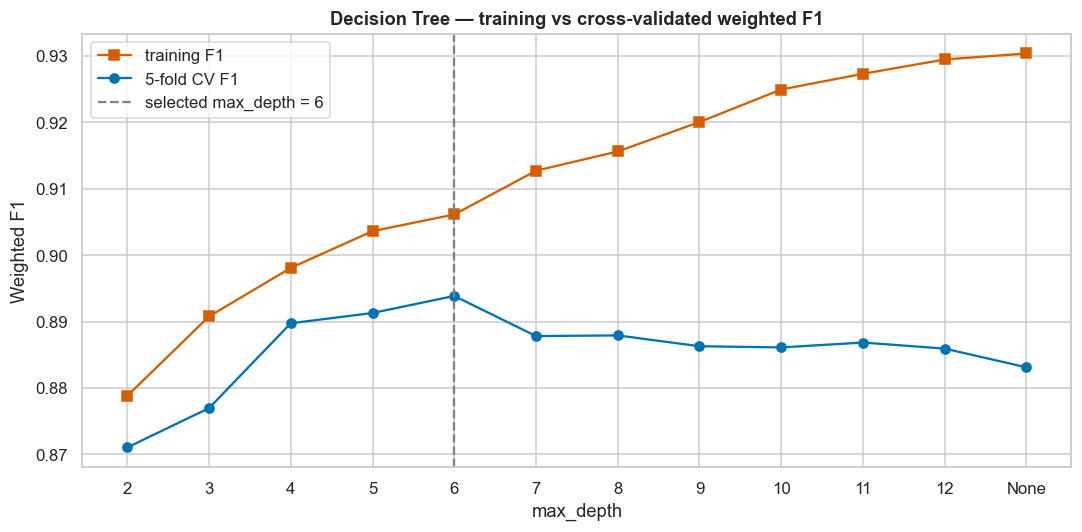

In [25]:
search = SEARCHES['Decision Tree']
c = cv_curve('Decision Tree', 'max_depth')
depth_labels = ['None' if str(d) in ('None', 'nan') else str(int(float(d))) for d in c['max_depth']]

# Training-set score for the same depths shows over-fitting explicitly
train_scores = []
for d in depth_labels:
    d = None if d == 'None' else int(d)
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE,
                               **{k: v for k, v in search.best_params_.items() if k != 'max_depth'})
    train_scores.append(f1_score(y_train, m.fit(X_train_p, y_train).predict(X_train_p), average='weighted'))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(depth_labels, train_scores, marker='s', color=PALETTE[3], label='training F1')
ax.plot(depth_labels, c['mean_test_score'], marker='o', color=PALETTE[0], label='5-fold CV F1')
ax.axvline(str(search.best_params_['max_depth']), ls='--', color='grey',
           label=f"selected max_depth = {search.best_params_['max_depth']}")
ax.set(title='Decision Tree — training vs cross-validated weighted F1', xlabel='max_depth',
       ylabel='Weighted F1')
ax.legend()
plt.tight_layout(); save_fig(fig, 'dt_depth_curve'); plt.show()

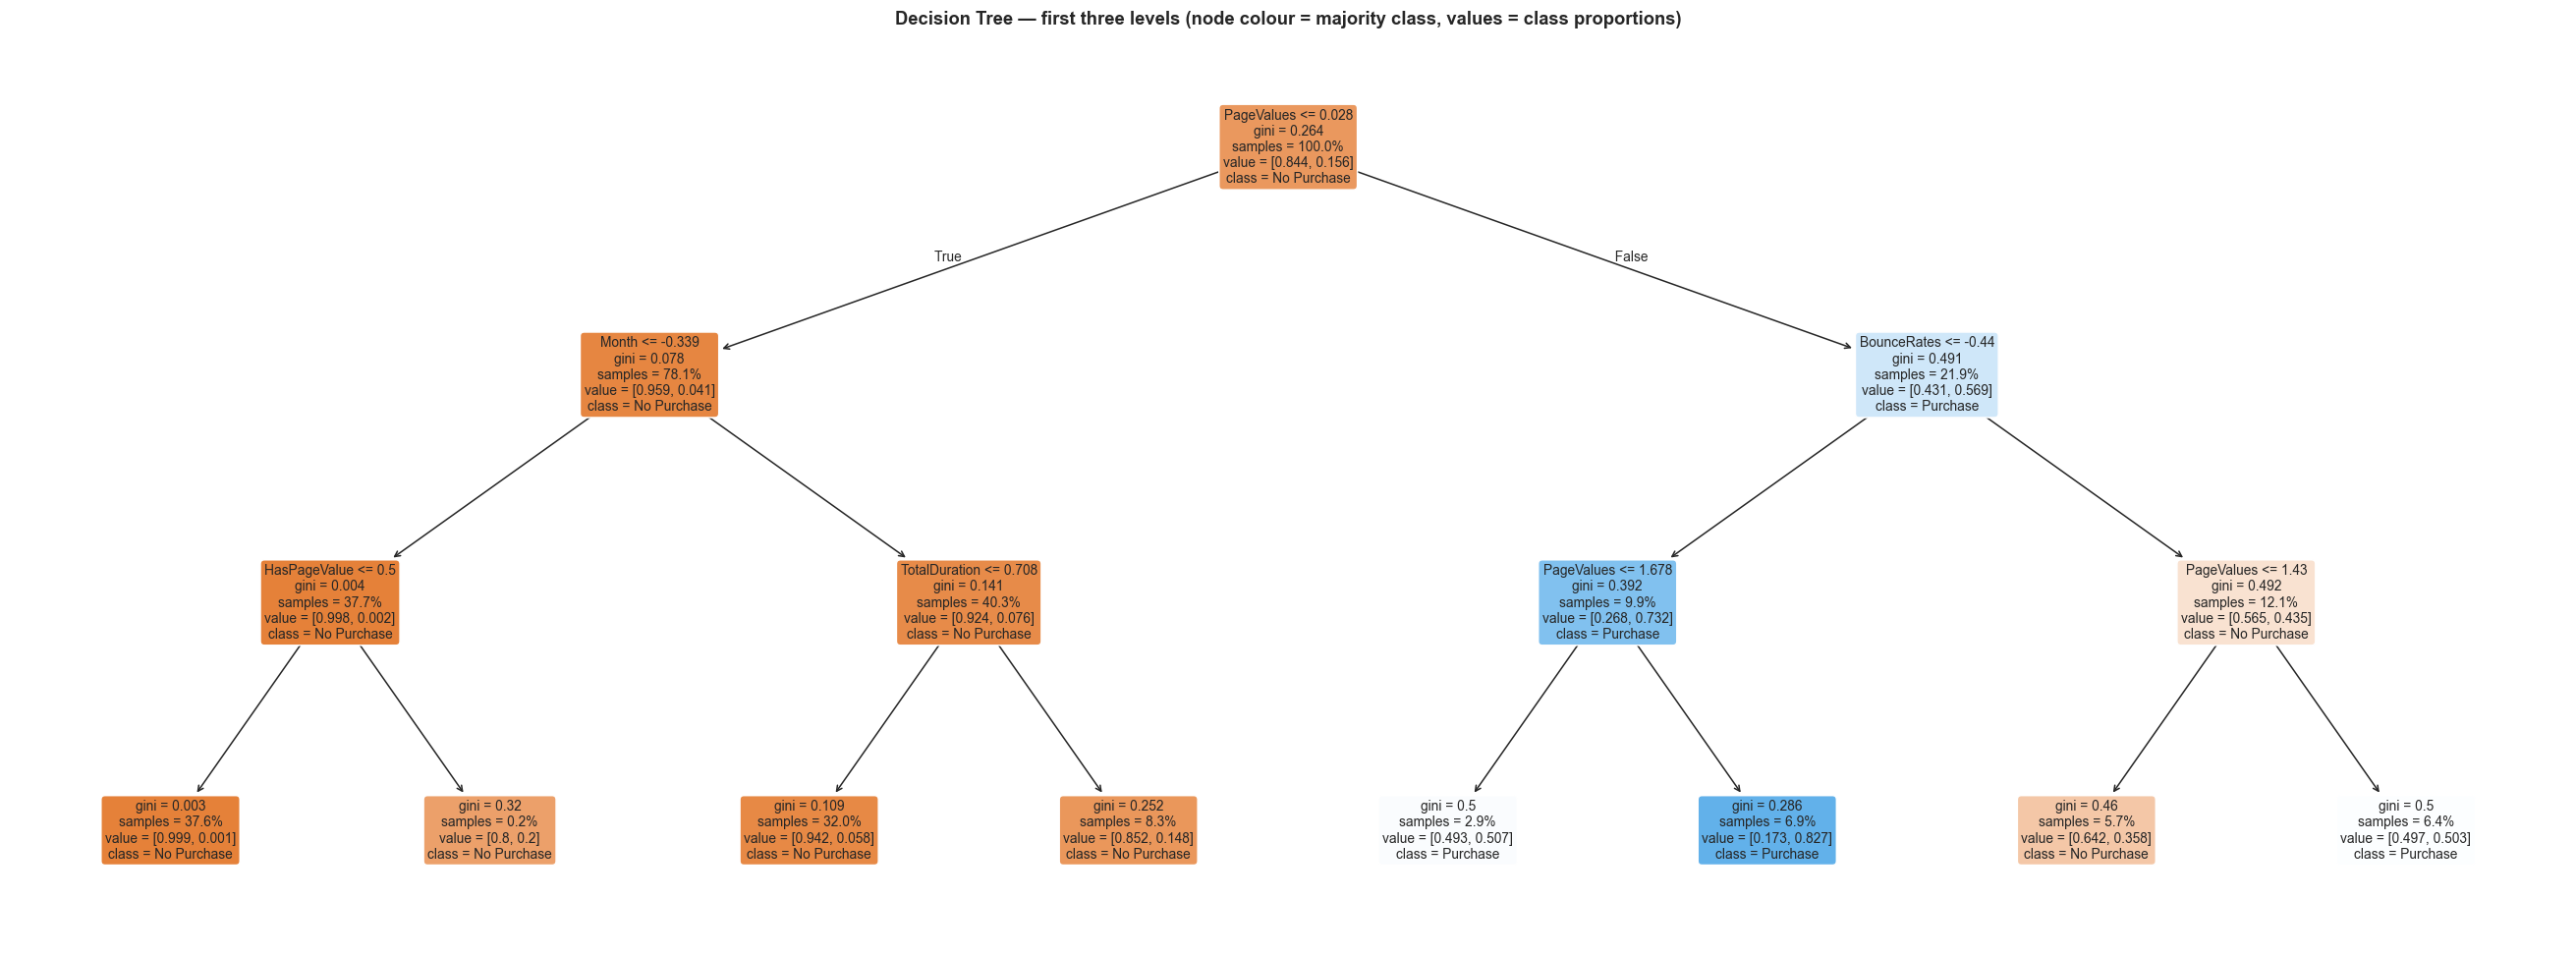

In [26]:
# Visualise the top of the tree (depth 3 for readability; same features & criterion as the tuned tree)
viz_tree = DecisionTreeClassifier(max_depth=3, criterion=search.best_params_['criterion'],
                                  random_state=RANDOM_STATE).fit(X_train_p, y_train)
fig, ax = plt.subplots(figsize=(24, 9))
plot_tree(viz_tree, feature_names=X_train_p.columns, class_names=CLASS_NAMES, filled=True,
          rounded=True, proportion=True, fontsize=9, ax=ax)
ax.set_title('Decision Tree — first three levels (node colour = majority class, values = class proportions)')
plt.tight_layout(); save_fig(fig, 'decision_tree'); plt.show()

**📝 Observations — Decision Tree**
- The unpruned default tree memorises the training data and over-fits badly: test F1 is only 0.860 and ROC-AUC 0.741. The depth/leaf-size search selects **max_depth = 6, min_samples_leaf = 10**, which gives **test F1 0.8924 and ROC-AUC 0.9174**, the largest tuning gain of all ten models.
- The depth curve shows the classic **bias–variance trade-off**: training F1 keeps rising with depth (0.879 → 0.930), while CV F1 peaks at **depth 6 (0.894)** and then falls. Deeper trees fit noise.
- **Tree visualisation:** the root split is on **`PageValues`** (78 % of sessions have none, and only 4.1 % of them buy). For those sessions the next split is **`Month`**: early-year months are almost pure "No Purchase". For sessions *with* a page value, the next split is **`BounceRates`**: a low bounce rate gives a 57 % → 83 % purchase node. These are the same drivers found in the EDA, in a form that can be explained to a marketing team.

### 5.5 Support Vector Machine (SVC) — tune `C` and `kernel` on scaled features
Finds the maximum-margin boundary; the RBF kernel lets that boundary be non-linear. SVC is scale-sensitive, which is
why every numerical feature was standardised in §3.5. ROC-AUC uses the SVM decision score.

In [27]:
svc_base, svc_best = run_model(
    'Support Vector Machine', 'A',
    SVC(random_state=RANDOM_STATE),
    [{'kernel': ['linear'], 'C': [0.1, 1, 10]},
     {'kernel': ['rbf'], 'C': [0.1, 1, 10], 'gamma': ['scale', 0.01]}])

Support Vector Machine: 9 candidates × 5 folds in 16.3s
  best params : {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
  best CV F1  : 0.8916


,Accuracy,Precision (w),Recall (w),F1 (w),ROC-AUC,Purchase Recall,Purchase F1
Stage,,,,,,,
Baseline,0.9021,0.8960,0.9021,0.8975,0.8785,0.5864,0.6521
Tuned,0.9021,0.8960,0.9021,0.8975,0.8785,0.5864,0.6521


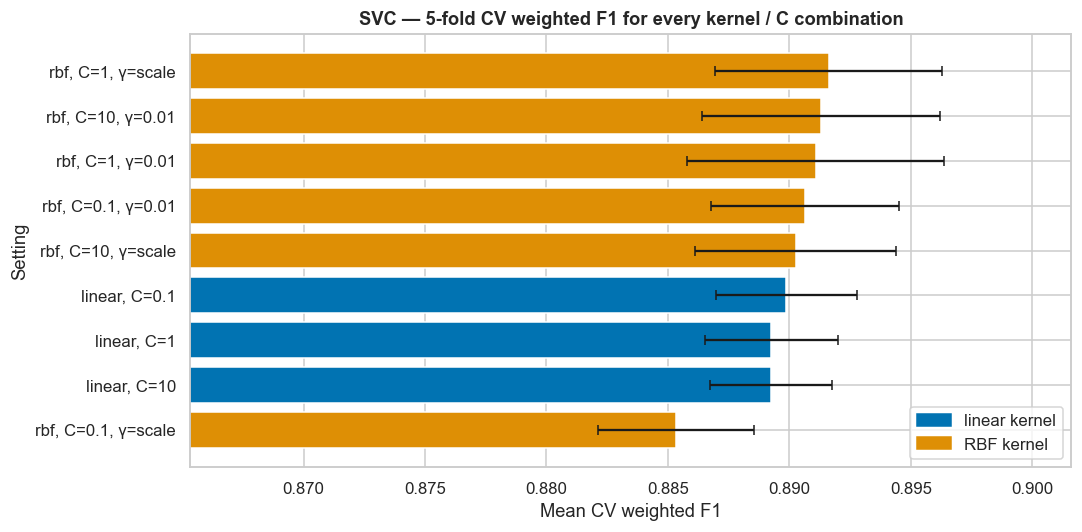

In [28]:
res = pd.DataFrame(SEARCHES['Support Vector Machine'].cv_results_)
res['setting'] = res['params'].apply(lambda p: f"{p['kernel']}, C={p['C']}" + (f", γ={p['gamma']}" if 'gamma' in p else ''))
res = res.sort_values('mean_test_score')
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(res['setting'], res['mean_test_score'], xerr=res['std_test_score'],
        color=[PALETTE[1] if 'rbf' in s else PALETTE[0] for s in res['setting']], capsize=3)
ax.set(title='SVC — 5-fold CV weighted F1 for every kernel / C combination', xlabel='Mean CV weighted F1',
       ylabel='Setting', xlim=(res['mean_test_score'].min() - 0.02, res['mean_test_score'].max() + 0.01))
ax.legend(handles=[Patch(color=PALETTE[0], label='linear kernel'), Patch(color=PALETTE[1], label='RBF kernel')])
plt.tight_layout(); save_fig(fig, 'svc_grid'); plt.show()

**📝 Observations — Support Vector Machine**
- The grid selected the **RBF kernel with C = 1 and gamma = 'scale'**, which are the library defaults, so baseline and tuned are identical (test F1 **0.8975**, the best of Part A).
- The five best settings all use the RBF kernel; only the strongly regularised RBF model (C = 0.1, gamma = 'scale') falls below the linear kernel. The class boundary is mildly non-linear, which matches the threshold-like relationships in §2.5. The differences are small (< 0.007 F1) relative to the fold-to-fold spread.
- **C trade-off:** larger C means a narrower margin and fewer training errors, but higher variance. C = 10 did not improve CV F1, and C = 0.1 under-fits.
- SVC's ROC-AUC (0.879) is lower than that of LR or the tree, even though its F1 is higher. The SVM decision score is a distance to the margin, not a calibrated probability, so it ranks sessions far from the boundary less consistently.
- Scaling is essential: SVC uses distances in feature space, so an unscaled duration in seconds would dominate everything else.

### 5.6 Part A — preliminary comparison and confusion matrices

,Model,Part,Accuracy,Precision (w),Recall (w),F1 (w),ROC-AUC,Purchase Recall,Purchase F1
Rank,,,,,,,,,
1,Support Vector Machine,A,0.9021,0.8960,0.9021,0.8975,0.8785,0.5864,0.6521
2,Logistic Regression,A,0.8955,0.8914,0.8955,0.8931,0.9174,0.6126,0.6473
3,Decision Tree,A,0.8959,0.8905,0.8959,0.8924,0.9174,0.5916,0.6402
4,K-Nearest Neighbours,A,0.8890,0.8806,0.8890,0.8827,0.8986,0.5262,0.5973
5,Gaussian Naive Bayes,A,0.8251,0.8823,0.8251,0.8423,0.8691,0.8115,0.5922


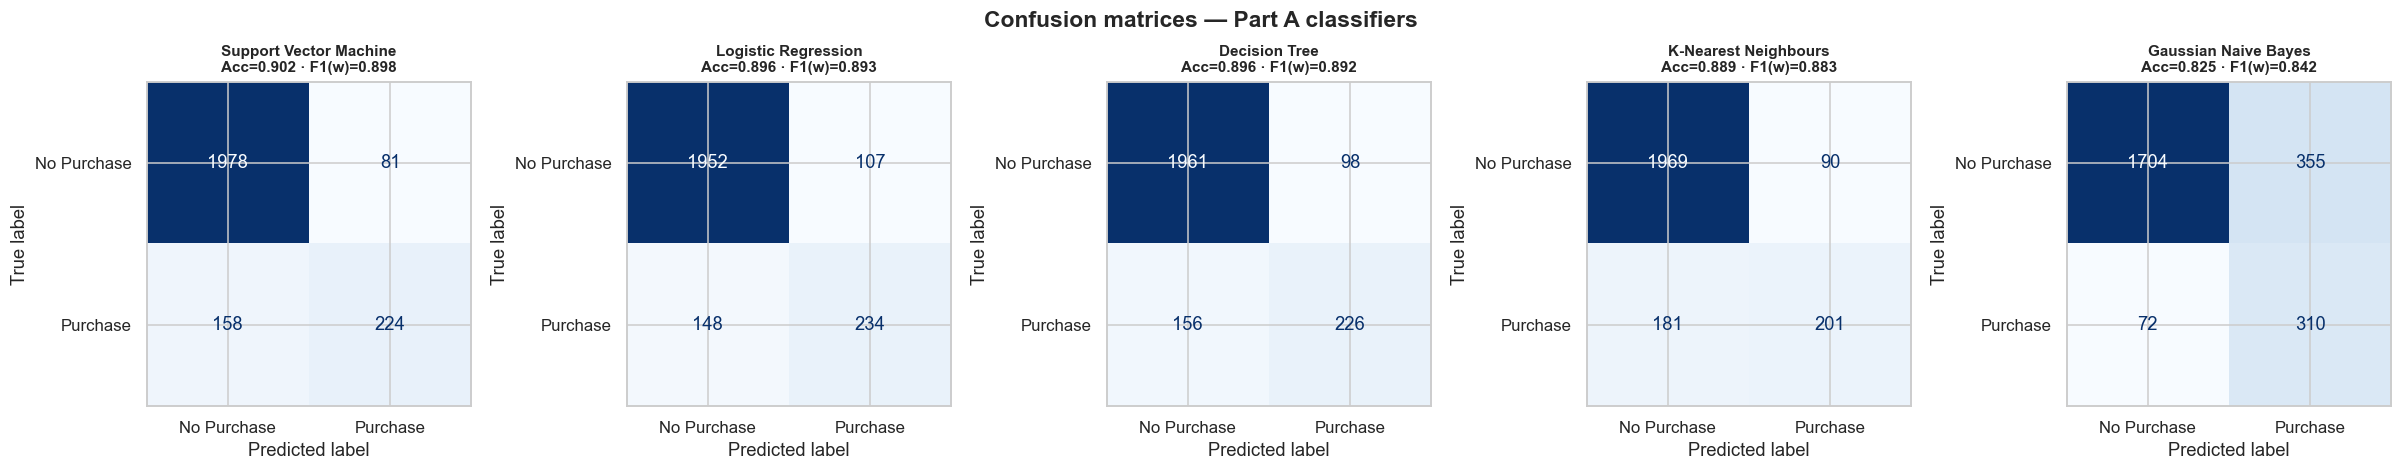

In [29]:
def results_table(stage='Tuned', part=None):
    rows = [{k: v for k, v in r.items() if k not in ('model', 'y_pred', 'y_score', 'cm')}
            for (n, s), r in RESULTS.items() if s == stage and (part is None or r['Part'] == part)]
    t = pd.DataFrame(rows).drop(columns='Stage').sort_values('F1 (w)', ascending=False).reset_index(drop=True)
    t.index = t.index + 1
    t.index.name = 'Rank'
    return t


def plot_confusion_matrices(names, title, fname, ncols=5):
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 4.2 * nrows))
    for ax, n in zip(np.atleast_1d(axes).flat, names):
        r = RESULTS[(n, 'Tuned')]
        ConfusionMatrixDisplay(r['cm'], display_labels=CLASS_NAMES).plot(ax=ax, cmap='Blues', colorbar=False)
        ax.set_title(f"{n}\nAcc={r['Accuracy']:.3f} · F1(w)={r['F1 (w)']:.3f}", fontsize=10)
        ax.set(xlabel='Predicted label', ylabel='True label')
    for ax in np.atleast_1d(axes).flat[len(names):]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=15, fontweight='bold')
    plt.tight_layout(); save_fig(fig, fname); plt.show()


part_a = results_table('Tuned', 'A')
display(part_a.style.format({c: '{:.4f}' for c in part_a.columns if c not in ('Model', 'Part')})
        .background_gradient(subset=['F1 (w)', 'ROC-AUC'], cmap='Greens')
        .set_caption('Part A — tuned models on the common test split'))
plot_confusion_matrices(part_a['Model'].tolist(), 'Confusion matrices — Part A classifiers', 'cm_part_a')

**📝 Observations — Part A summary**
- With CV-based tuning and the improved preprocessing, the Part A ranking by weighted F1 is **SVC (0.8975) > Logistic Regression (0.8931) > Decision Tree (0.8924) > KNN (0.8827) > Gaussian NB**. Compared with Review 1, SVC (0.8848 → 0.8975), Logistic Regression (0.8698 → 0.8931) and KNN (0.8648 → 0.8827) improved, mainly thanks to the log transform, one-hot encoding and `HasPageValue`. The Decision Tree is marginally lower (0.8950 → 0.8924) because its depth is now chosen by CV instead of on the test set, so the Review 1 figure was slightly optimistic. Gaussian NB dropped because the 0/1 one-hot columns break its Gaussian assumption.
- The four non-Bayesian models are within 1.5 F1 points of each other. Naive Bayes lags because its independence assumption fails on this data.
- The confusion matrices show the shared weakness: at the default threshold each model misses about 40 % of real buyers (Purchase recall 0.53–0.61), while Naive Bayes over-predicts purchases. This sets the target for Part B: catch more buyers without flooding the "Purchase" class with false alarms.

<div style="border: 4px solid #0891B2; border-radius: 14px; padding: 26px 30px; margin: 30px 0; background: linear-gradient(120deg, #ECFEFF 0%, #EEF2FF 100%);">

# 🚩 REVIEW 2 STARTS HERE — CLASSIFICATION PART B

**Everything above this cell (§0–§5) is Review 1 scope:** data audit, EDA, preprocessing, feature engineering and the
5 Part-A models (Logistic Regression, KNN, Gaussian Naive Bayes, Decision Tree, SVC).

**Everything below this cell is the Review 2 scope:**

| § | Content | Review 2 rubric |
|---|---------|-----------------|
| **6.1** | Random Forest Classifier — tune `n_estimators`, feature importance | A1 |
| **6.2** | AdaBoost Classifier — tune `n_estimators` and `learning_rate` | A1 |
| **6.3** | Gradient Boosting Classifier (sklearn GBM) — tune `learning_rate` | A1 |
| **6.4** | Bagging Classifier — Decision Tree as base estimator | A1 |
| **6.5** | MLP Classifier (neural network) — tune `hidden_layer_sizes` and `activation` | A1 |
| **7** | **Consolidated comparison of all 10 algorithms** (Accuracy, Precision, Recall, F1, ROC-AUC), tuning gains, confusion matrices, ROC & PR curves | A2 · D6 |
| **8** | **Final model selection** — 5-fold CV of the top-2, justification, learning curve, permutation importance, decision threshold | A3 |
| **9–10** | Saving the final model · conclusions | — |

Part B uses **exactly the same preprocessed data and the same stratified train/test split** as Part A (§3), so all ten models are directly comparable.

</div>

---
## 6 · Part B classifiers (Review 2)

Same preprocessed data, same split, same evaluation and the same tuning protocol as Part A.

### 6.1 Random Forest — tune `n_estimators`; feature importance
An ensemble of de-correlated decision trees (bootstrap rows + random feature subsets at each split); averaging many
high-variance trees lowers variance.

In [30]:
rf_base, rf_best = run_model(
    'Random Forest', 'B',
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    {'n_estimators': [100, 200, 400], 'max_depth': [None, 10, 20],
     'min_samples_leaf': [1, 3], 'max_features': ['sqrt', 0.5]})

Random Forest: 36 candidates × 5 folds in 84.9s
  best params : {'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 100}
  best CV F1  : 0.8990


,Accuracy,Precision (w),Recall (w),F1 (w),ROC-AUC,Purchase Recall,Purchase F1
Stage,,,,,,,
Baseline,0.9005,0.8947,0.9005,0.8963,0.9233,0.5916,0.6504
Tuned,0.9029,0.8979,0.9029,0.8995,0.9285,0.6126,0.6638


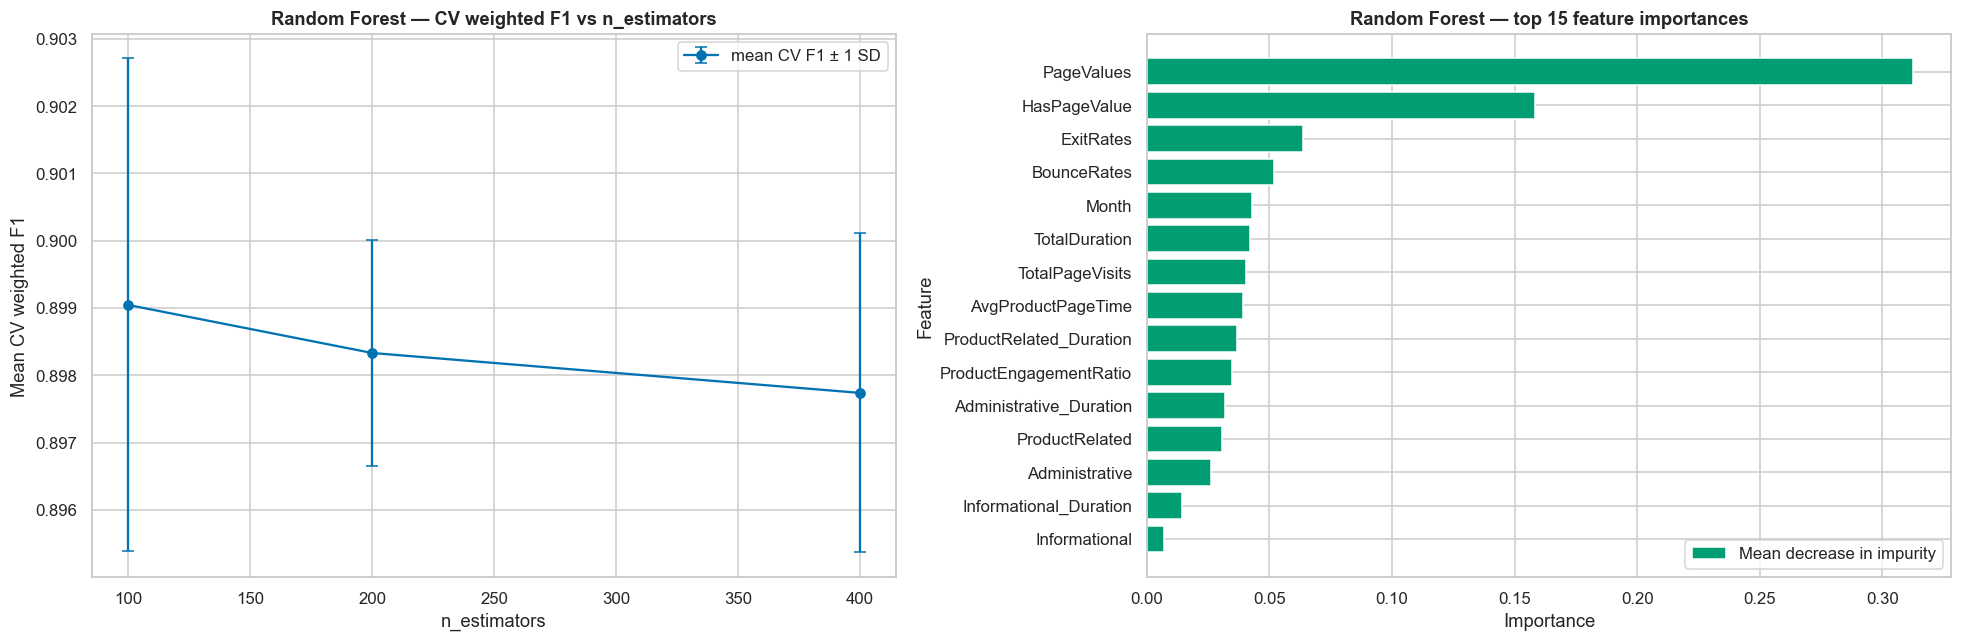

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
c = cv_curve('Random Forest', 'n_estimators')
axes[0].errorbar(c['n_estimators'].astype(int), c['mean_test_score'], yerr=c['std_test_score'],
                 marker='o', capsize=4, color=PALETTE[0], label='mean CV F1 ± 1 SD')
axes[0].set(title='Random Forest — CV weighted F1 vs n_estimators', xlabel='n_estimators',
            ylabel='Mean CV weighted F1')
axes[0].legend()

imp = pd.Series(rf_best.feature_importances_, index=X_train_p.columns).sort_values().tail(15)
axes[1].barh(imp.index, imp.values, color=PALETTE[2], label='Mean decrease in impurity')
axes[1].set(title='Random Forest — top 15 feature importances', xlabel='Importance', ylabel='Feature')
axes[1].legend(loc='lower right')
plt.tight_layout(); save_fig(fig, 'rf_tuning_importance'); plt.show()

**📝 Observations — Random Forest**
- The tuned forest (100 trees, max_depth = 20, max_features = 0.5, min_samples_leaf = 3) improves on the defaults: test **F1 0.8963 → 0.8995** and **ROC-AUC 0.9233 → 0.9285**. Limiting leaf size and depth reduces variance.
- **n_estimators:** mean CV F1 changes by only about 0.001 between 100, 200 and 400 trees, far less than its fold-to-fold standard deviation (~0.003). Once about 100 trees are averaged, adding more only costs time, which matches theory: averaging lowers variance until it plateaus.
- **Feature importance:** `PageValues` and the engineered `HasPageValue` dominate, followed by `ExitRates`, `BounceRates`, `Month` and the engagement features (`TotalDuration`, `TotalPageVisits`, `AvgProductPageTime`). Three of the five engineered features appear in the top 8, which supports the feature-engineering choices.

### 6.2 AdaBoost — tune `n_estimators` and `learning_rate`
Sequentially fits shallow trees (stumps), up-weighting the sessions the previous learners misclassified.

In [32]:
ada_base, ada_best = run_model(
    'AdaBoost', 'B',
    AdaBoostClassifier(random_state=RANDOM_STATE),
    {'n_estimators': [25, 50, 100, 200, 400], 'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0]})

AdaBoost: 25 candidates × 5 folds in 45.4s
  best params : {'learning_rate': 0.1, 'n_estimators': 25}
  best CV F1  : 0.8889


,Accuracy,Precision (w),Recall (w),F1 (w),ROC-AUC,Purchase Recall,Purchase F1
Stage,,,,,,,
Baseline,0.8918,0.8894,0.8918,0.8905,0.9219,0.6257,0.6442
Tuned,0.8873,0.8865,0.8873,0.8869,0.9015,0.6309,0.6367


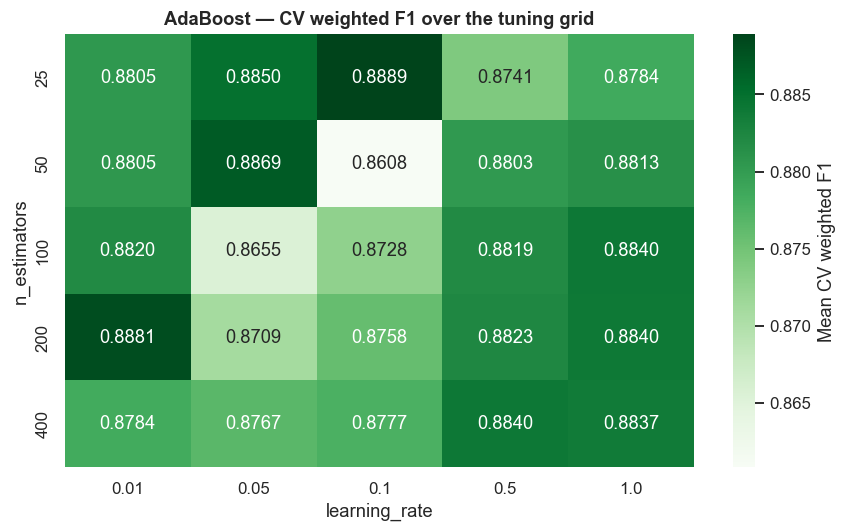

In [33]:
res = pd.DataFrame(SEARCHES['AdaBoost'].cv_results_)
heat = res.pivot_table(index='param_n_estimators', columns='param_learning_rate', values='mean_test_score')
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt='.4f', cmap='Greens', cbar_kws={'label': 'Mean CV weighted F1'}, ax=ax)
ax.set(title='AdaBoost — CV weighted F1 over the tuning grid', xlabel='learning_rate', ylabel='n_estimators')
plt.tight_layout(); save_fig(fig, 'ada_grid'); plt.show()

**📝 Observations — AdaBoost**
- The CV surface is **irregular** (0.861–0.889): AdaBoost is sensitive to the exact combination of settings. The two best cells, 25 stumps × learning rate 0.1 and 200 stumps × 0.01, both use a *small total amount of boosting* (n_estimators × learning_rate ≈ 2–2.5). This is the expected trade-off: a smaller learning rate needs more rounds, and too much boosting makes AdaBoost chase the hardest (often noisy) sessions.
- On the test split the tuned model is marginally below the default (F1 0.8869 vs 0.8905). AdaBoost's Purchase recall (≈ 0.63) is however higher than that of the other ensembles: re-weighting misclassified sessions pushes it to find more buyers.
- AdaBoost ranks in the lower half, behind Gradient Boosting. Exponential-loss boosting of stumps is more sensitive to noisy labels than gradient boosting of deeper trees on log-loss.

### 6.3 Gradient Boosting (scikit-learn GBM) — tune `learning_rate`
Adds trees one at a time, each fitted to the gradient of the log-loss of the current ensemble. `learning_rate` and
`n_estimators` trade off against each other; `max_depth` and `subsample` control complexity.

In [34]:
gb_base, gb_best = run_model(
    'Gradient Boosting', 'B',
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    {'learning_rate': [0.03, 0.05, 0.1, 0.2], 'n_estimators': [100, 200, 300],
     'max_depth': [2, 3, 4], 'subsample': [0.8, 1.0]})

Gradient Boosting: 72 candidates × 5 folds in 225.6s
  best params : {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 200, 'subsample': 1.0}
  best CV F1  : 0.8991


,Accuracy,Precision (w),Recall (w),F1 (w),ROC-AUC,Purchase Recall,Purchase F1
Stage,,,,,,,
Baseline,0.9005,0.8961,0.9005,0.8977,0.9354,0.6204,0.6611
Tuned,0.9029,0.8982,0.9029,0.8998,0.9358,0.6178,0.6657


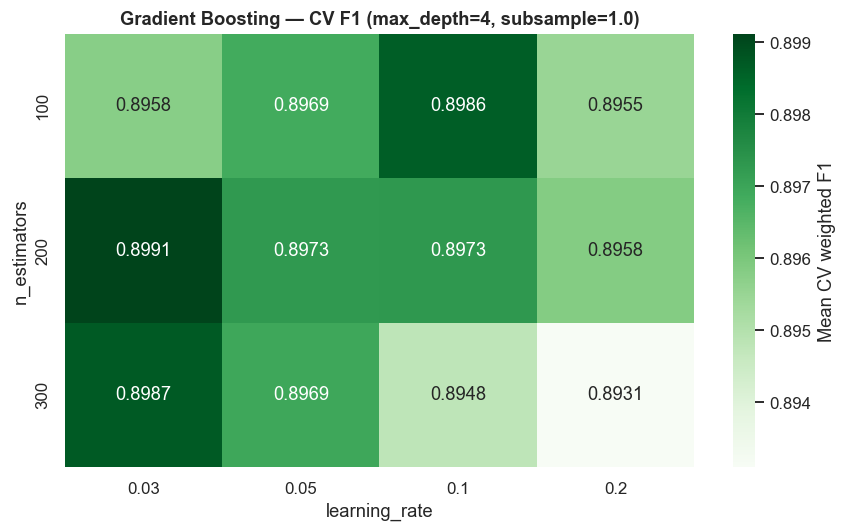

In [35]:
res = pd.DataFrame(SEARCHES['Gradient Boosting'].cv_results_)
bp = SEARCHES['Gradient Boosting'].best_params_
sub = res[(res['param_max_depth'] == bp['max_depth']) & (res['param_subsample'] == bp['subsample'])]
heat = sub.pivot_table(index='param_n_estimators', columns='param_learning_rate', values='mean_test_score')
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt='.4f', cmap='Greens', cbar_kws={'label': 'Mean CV weighted F1'}, ax=ax)
ax.set(title=f"Gradient Boosting — CV F1 (max_depth={bp['max_depth']}, subsample={bp['subsample']})",
       xlabel='learning_rate', ylabel='n_estimators')
plt.tight_layout(); save_fig(fig, 'gb_grid'); plt.show()

**📝 Observations — Gradient Boosting**
- The best configuration is **learning_rate = 0.03, n_estimators = 200, max_depth = 4, subsample = 1.0** (CV F1 0.8991). Test results: **weighted F1 0.8998, ROC-AUC 0.9358**, the best of all ten models on both metrics.
- **learning_rate:** the heatmap shows the expected trade-off. A small learning rate needs more trees, and a large one with many trees starts to over-fit, so CV F1 drops. Small steps with moderate depth generalise best.
- Even the default GBM is very strong (F1 0.8977, AUC 0.9354), so tuning gives a modest but consistent gain (+0.0020 F1, +0.0004 AUC).

### 6.4 Bagging — Decision Tree as the base estimator
Trains many decision trees on bootstrap samples and takes a majority vote. Unlike Random Forest, every split may use
**all** features, so the trees are more correlated.

In [36]:
bag_base, bag_best = run_model(
    'Bagging (Decision Tree)', 'B',
    BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE), random_state=RANDOM_STATE),
    {'n_estimators': [50, 100, 200], 'max_samples': [0.5, 0.8, 1.0],
     'estimator__max_depth': [None, 8, 12]})

Bagging (Decision Tree): 27 candidates × 5 folds in 56.4s
  best params : {'estimator__max_depth': 8, 'max_samples': 0.8, 'n_estimators': 200}
  best CV F1  : 0.8984


,Accuracy,Precision (w),Recall (w),F1 (w),ROC-AUC,Purchase Recall,Purchase F1
Stage,,,,,,,
Baseline,0.8906,0.8839,0.8906,0.8861,0.8966,0.5602,0.6158
Tuned,0.9017,0.8972,0.9017,0.8988,0.9326,0.6204,0.6639


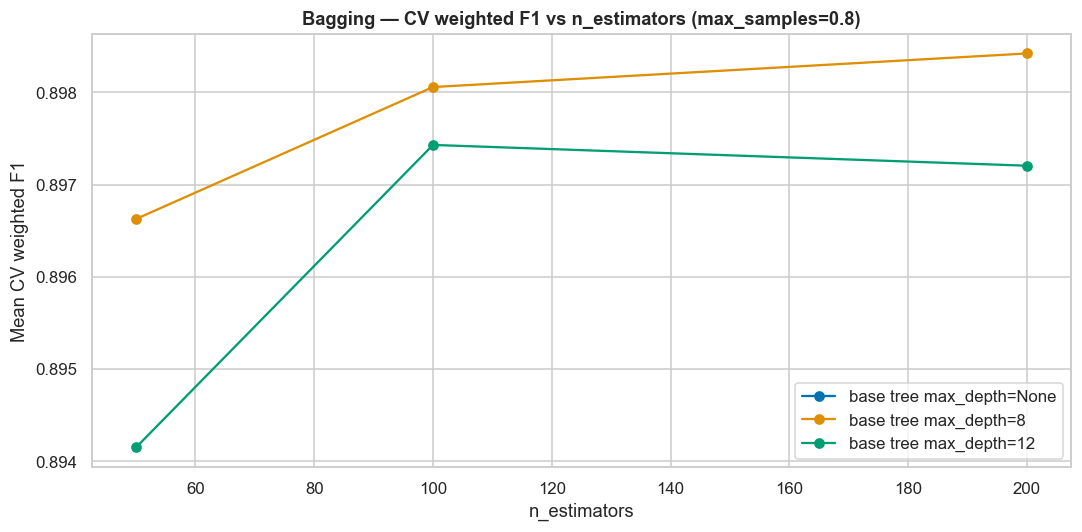

In [37]:
fig, ax = plt.subplots(figsize=(10, 5))
res = pd.DataFrame(SEARCHES['Bagging (Decision Tree)'].cv_results_)
bp = SEARCHES['Bagging (Decision Tree)'].best_params_
for depth, color in zip([None, 8, 12], PALETTE):
    s = res[(res['param_estimator__max_depth'].astype(str) == str(depth))
            & (res['param_max_samples'] == bp['max_samples'])].sort_values('param_n_estimators')
    ax.plot(s['param_n_estimators'].astype(int), s['mean_test_score'], marker='o', color=color,
            label=f'base tree max_depth={depth}')
ax.set(title=f"Bagging — CV weighted F1 vs n_estimators (max_samples={bp['max_samples']})",
       xlabel='n_estimators', ylabel='Mean CV weighted F1')
ax.legend()
plt.tight_layout(); save_fig(fig, 'bagging_curve'); plt.show()

**📝 Observations — Bagging (Decision Tree base)**
- Bagging **fully grown** trees (the default) gives F1 0.8861 and ROC-AUC 0.8966. Each bootstrap tree still over-fits, and the trees are highly correlated because each one can split on the dominant `PageValues` feature.
- Limiting the base tree to **max_depth = 8** with 200 estimators and 80 % bootstrap samples raises F1 to **0.8988** and ROC-AUC to **0.9326** (+0.036), one of the largest tuning gains.
- Bagging ends up just behind Random Forest. The forest's extra feature subsampling de-correlates the trees further, which is exactly the difference between the two algorithms.

### 6.5 MLP Classifier (neural network) — tune `hidden_layer_sizes` and `activation`
A feed-forward network trained with Adam. `early_stopping=True` holds out 10 % of the training fold and stops when the
validation score stops improving; `alpha` is the L2 penalty.

In [38]:
mlp_base, mlp_best = run_model(
    'MLP Neural Network', 'B',
    MLPClassifier(max_iter=500, random_state=RANDOM_STATE),
    {'hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64)],
     'activation': ['relu', 'tanh'], 'alpha': [1e-4, 1e-3, 1e-2],
     'early_stopping': [True]})

MLP Neural Network: 30 candidates × 5 folds in 9.1s
  best params : {'activation': 'tanh', 'alpha': 0.01, 'early_stopping': True, 'hidden_layer_sizes': (64, 32)}
  best CV F1  : 0.8939


,Accuracy,Precision (w),Recall (w),F1 (w),ROC-AUC,Purchase Recall,Purchase F1
Stage,,,,,,,
Baseline,0.8763,0.8716,0.8763,0.8736,0.8844,0.5550,0.5840
Tuned,0.8996,0.8958,0.8996,0.8973,0.9271,0.6257,0.6611


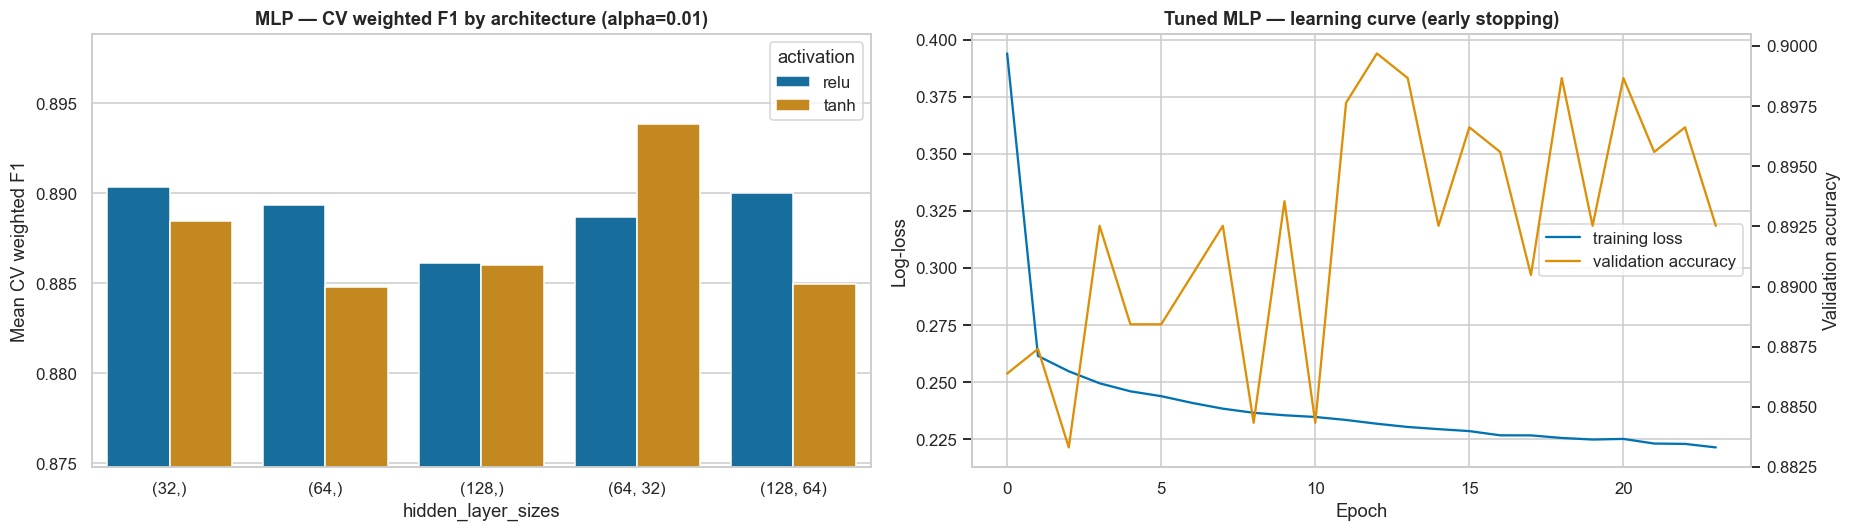

In [39]:
res = pd.DataFrame(SEARCHES['MLP Neural Network'].cv_results_)
res['hidden'] = res['param_hidden_layer_sizes'].astype(str)
bp = SEARCHES['MLP Neural Network'].best_params_
sub = res[res['param_alpha'] == bp['alpha']]
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sns.barplot(data=sub, x='hidden', y='mean_test_score', hue='param_activation', ax=axes[0], palette='colorblind')
axes[0].set(title=f"MLP — CV weighted F1 by architecture (alpha={bp['alpha']})", xlabel='hidden_layer_sizes',
            ylabel='Mean CV weighted F1', ylim=(sub['mean_test_score'].min() - 0.01, sub['mean_test_score'].max() + 0.005))
axes[0].legend(title='activation')
axes[1].plot(mlp_best.loss_curve_, color=PALETTE[0], label='training loss')
ax2 = axes[1].twinx()
ax2.plot(mlp_best.validation_scores_, color=PALETTE[1], label='validation accuracy'); ax2.grid(False)
ax2.set_ylabel('Validation accuracy')
axes[1].set(title='Tuned MLP — learning curve (early stopping)', xlabel='Epoch', ylabel='Log-loss')
h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, loc='center right')
plt.tight_layout(); save_fig(fig, 'mlp_tuning'); plt.show()

**📝 Observations — MLP neural network**
- The default MLP (one hidden layer of 100 ReLU units, very weak L2 penalty) over-fits: F1 0.8736, ROC-AUC 0.8844.
- The grid selected **two hidden layers (64, 32), tanh activation, alpha = 0.01, early stopping**. This raises F1 to **0.8973** and ROC-AUC to **0.9271**, an F1 gain of +0.024.
- **Activation and architecture:** at the selected alpha every architecture/activation scores within about one F1 point (0.885–0.894). The two-layer tanh network is best, while ReLU is slightly better for most single-layer networks. Regularisation (`alpha`, early stopping) improved the model more than the choice of architecture.
- The learning curve shows the training loss falling smoothly while the validation accuracy fluctuates around 0.89. Early stopping halted training after about 24 epochs, once validation accuracy stopped improving, which prevents over-fitting without a manual epoch count.

---
## 7 · Consolidated comparison of all 10 algorithms  *(Review 2 deliverable D6)*

One table, one test split (2,441 sessions), every mandatory metric. Models are ranked by weighted F1; Precision,
Recall and F1 are **weighted** averages over both classes.

In [40]:
final_table = results_table('Tuned')
metric_cols = ['Accuracy', 'Precision (w)', 'Recall (w)', 'F1 (w)', 'ROC-AUC', 'Purchase Recall', 'Purchase F1']
display(final_table.style.format({c: '{:.4f}' for c in metric_cols})
        .background_gradient(subset=metric_cols, cmap='Greens')
        .set_caption('Consolidated 10-algorithm comparison (tuned models, common test split)'))
final_table.to_csv(REPORTS_DIR / 'classification_comparison.csv', index_label='Rank', float_format='%.4f')

,Model,Part,Accuracy,Precision (w),Recall (w),F1 (w),ROC-AUC,Purchase Recall,Purchase F1
Rank,,,,,,,,,
1,Gradient Boosting,B,0.9029,0.8982,0.9029,0.8998,0.9358,0.6178,0.6657
2,Random Forest,B,0.9029,0.8979,0.9029,0.8995,0.9285,0.6126,0.6638
3,Bagging (Decision Tree),B,0.9017,0.8972,0.9017,0.8988,0.9326,0.6204,0.6639
4,Support Vector Machine,A,0.9021,0.8960,0.9021,0.8975,0.8785,0.5864,0.6521
5,MLP Neural Network,B,0.8996,0.8958,0.8996,0.8973,0.9271,0.6257,0.6611
6,Logistic Regression,A,0.8955,0.8914,0.8955,0.8931,0.9174,0.6126,0.6473
7,Decision Tree,A,0.8959,0.8905,0.8959,0.8924,0.9174,0.5916,0.6402
8,AdaBoost,B,0.8873,0.8865,0.8873,0.8869,0.9015,0.6309,0.6367
9,K-Nearest Neighbours,A,0.8890,0.8806,0.8890,0.8827,0.8986,0.5262,0.5973


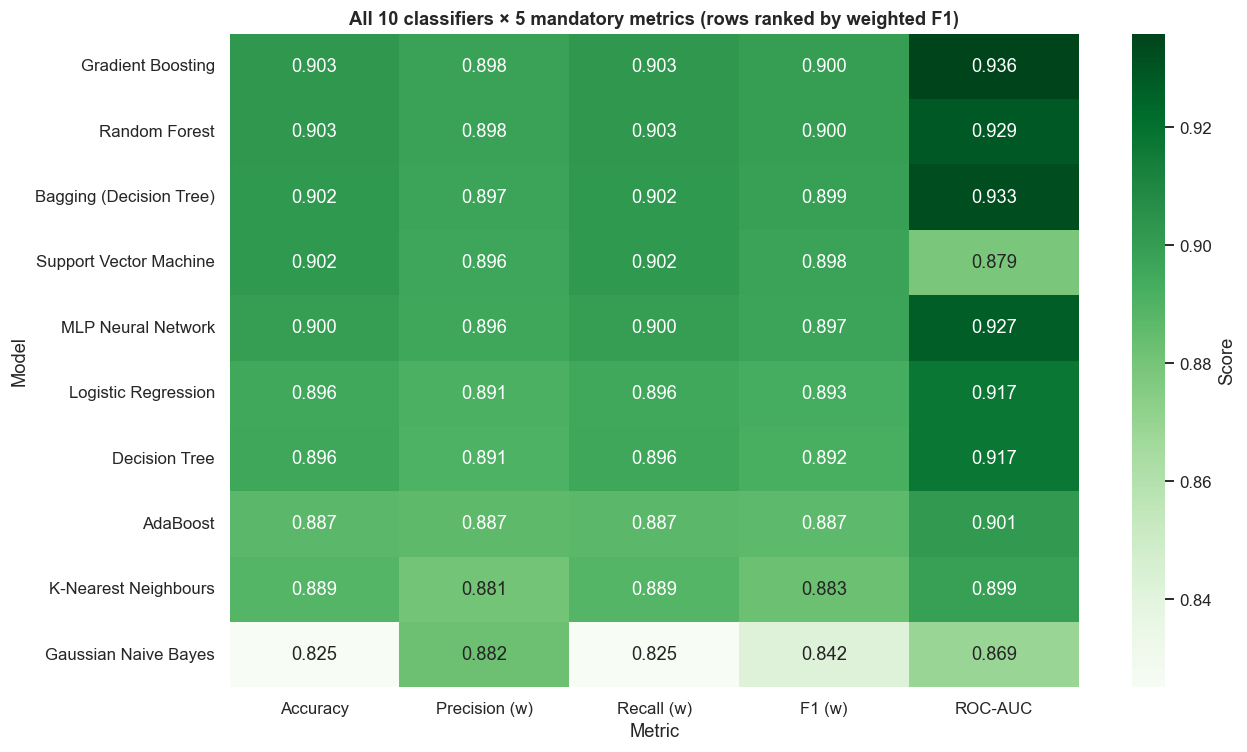

In [41]:
fig, ax = plt.subplots(figsize=(12, 7))
heat = final_table.set_index('Model')[['Accuracy', 'Precision (w)', 'Recall (w)', 'F1 (w)', 'ROC-AUC']]
sns.heatmap(heat, annot=True, fmt='.3f', cmap='Greens', cbar_kws={'label': 'Score'}, ax=ax)
ax.set(title='All 10 classifiers × 5 mandatory metrics (rows ranked by weighted F1)', xlabel='Metric', ylabel='Model')
plt.tight_layout(); save_fig(fig, 'comparison_heatmap'); plt.show()

**📝 Observations — consolidated comparison**
- **Gradient Boosting ranks first on weighted F1 (0.8998) and ROC-AUC (0.9358)**, closely followed by Random Forest (0.8995 / 0.9285) and Bagging (0.8988 / 0.9326). The three tree ensembles take the top three places.
- The top seven models are within **0.75 F1 points** of each other (0.8924–0.8998). On a test set of 2,441 sessions a difference of 0.002 is about 5 sessions, so the ranking near the top **must be confirmed by cross-validation** (§8).
- **ROC-AUC tells a different story for SVC.** It is 4th by F1 but has the second-lowest AUC (0.879, only Naive Bayes is lower), because its decision scores are poorly calibrated for ranking.
- Gaussian NB is last on F1 but has by far the highest **Purchase recall**. If missing a buyer were much more costly than a false alarm, NB's behaviour could be acceptable, which shows that the "best" model depends on the business cost of each error type.
- Every model except Naive Bayes beats the 84.5 % "always No" accuracy baseline. Naive Bayes trades accuracy for recall.

### 7.1 Effect of hyper-parameter tuning (baseline → tuned, test split)

,Part,Best parameters,F1 (w) baseline,F1 (w) tuned,Δ F1 (w),ROC-AUC baseline,ROC-AUC tuned,Δ ROC-AUC
Model,,,,,,,,
Gradient Boosting,B,"{'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 200, 'subsample': 1.0}",0.8977,0.8998,+0.0020,0.9354,0.9358,+0.0004
Random Forest,B,"{'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 100}",0.8963,0.8995,+0.0032,0.9233,0.9285,+0.0052
Bagging (Decision Tree),B,"{'estimator__max_depth': 8, 'max_samples': 0.8, 'n_estimators': 200}",0.8861,0.8988,+0.0127,0.8966,0.9326,+0.0360
Support Vector Machine,A,"{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}",0.8975,0.8975,+0.0000,0.8785,0.8785,+0.0000
MLP Neural Network,B,"{'activation': 'tanh', 'alpha': 0.01, 'early_stopping': True, 'hidden_layer_sizes': (64, 32)}",0.8736,0.8973,+0.0237,0.8844,0.9271,+0.0427
Logistic Regression,A,{'C': 1},0.8931,0.8931,+0.0000,0.9174,0.9174,+0.0000
Decision Tree,A,"{'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 10}",0.8601,0.8924,+0.0323,0.7406,0.9174,+0.1769
AdaBoost,B,"{'learning_rate': 0.1, 'n_estimators': 25}",0.8905,0.8869,-0.0036,0.9219,0.9015,-0.0205
K-Nearest Neighbours,A,"{'metric': 'euclidean', 'n_neighbors': 17, 'weights': 'uniform'}",0.8870,0.8827,-0.0044,0.8666,0.8986,+0.0321


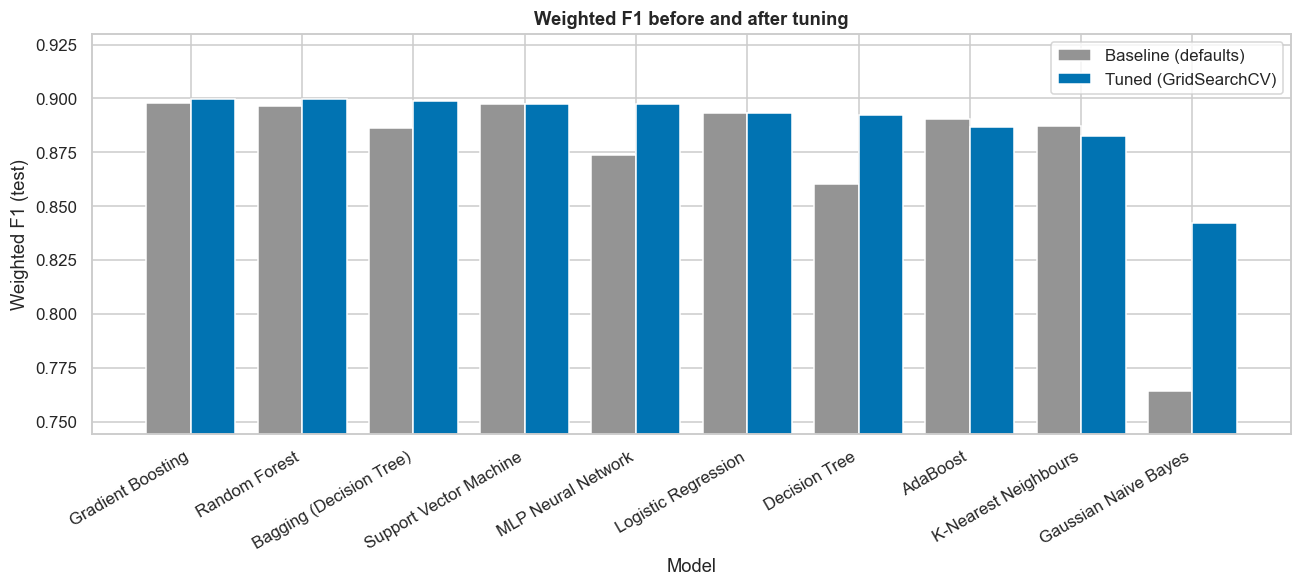

In [42]:
base_t = results_table('Baseline').set_index('Model')
tuned_t = final_table.set_index('Model')
gain = pd.DataFrame({
    'Part': tuned_t['Part'],
    'Best parameters': pd.Series({n: str(fmt_params(s.best_params_)) for n, s in SEARCHES.items()}),
    'F1 (w) baseline': base_t['F1 (w)'], 'F1 (w) tuned': tuned_t['F1 (w)'],
    'Δ F1 (w)': tuned_t['F1 (w)'] - base_t['F1 (w)'],
    'ROC-AUC baseline': base_t['ROC-AUC'], 'ROC-AUC tuned': tuned_t['ROC-AUC'],
    'Δ ROC-AUC': tuned_t['ROC-AUC'] - base_t['ROC-AUC'],
}).loc[tuned_t.index]
display(gain.style.format({c: '{:+.4f}' if c.startswith('Δ') else '{:.4f}' for c in gain.columns
                           if c not in ('Part', 'Best parameters')})
        .bar(subset=['Δ F1 (w)', 'Δ ROC-AUC'], align='zero', color=['#d65f5f', '#5fba7d']))
gain.to_csv(REPORTS_DIR / 'classification_tuning_gains.csv', float_format='%.4f')

fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(gain))
ax.bar(x - 0.2, gain['F1 (w) baseline'], 0.4, label='Baseline (defaults)', color=PALETTE[7])
ax.bar(x + 0.2, gain['F1 (w) tuned'], 0.4, label='Tuned (GridSearchCV)', color=PALETTE[0])
ax.set_xticks(x, gain.index, rotation=30, ha='right')
ax.set(title='Weighted F1 before and after tuning', xlabel='Model', ylabel='Weighted F1 (test)',
       ylim=(gain[['F1 (w) baseline', 'F1 (w) tuned']].min().min() - 0.02, 0.93))
ax.legend()
plt.tight_layout(); save_fig(fig, 'tuning_gain'); plt.show()

**📝 Observations — effect of tuning**
- Tuning gave the biggest gains to the **high-variance learners**: Gaussian NB, Decision Tree (+0.032 F1, +0.177 AUC), MLP (+0.024 / +0.043) and Bagging (+0.013 / +0.036). In every case the gain came from **adding regularisation** (depth/leaf limits, L2 penalty, variance smoothing).
- For Logistic Regression and SVC the CV search confirmed the library defaults (Δ = 0).
- For KNN and AdaBoost the CV-optimal settings are about equal to, or marginally worse than, the defaults on this *particular* test split. That is expected occasionally: hyper-parameters were chosen by 5-fold CV on the training data, *not* by looking at the test set, so the test score is an honest estimate rather than an optimised one.
- **Rubric A3:** the final model (Gradient Boosting) improved from **F1 0.8977 → 0.8998** and **ROC-AUC 0.9354 → 0.9358** after GridSearchCV.

### 7.2 Confusion matrices — all 10 tuned models

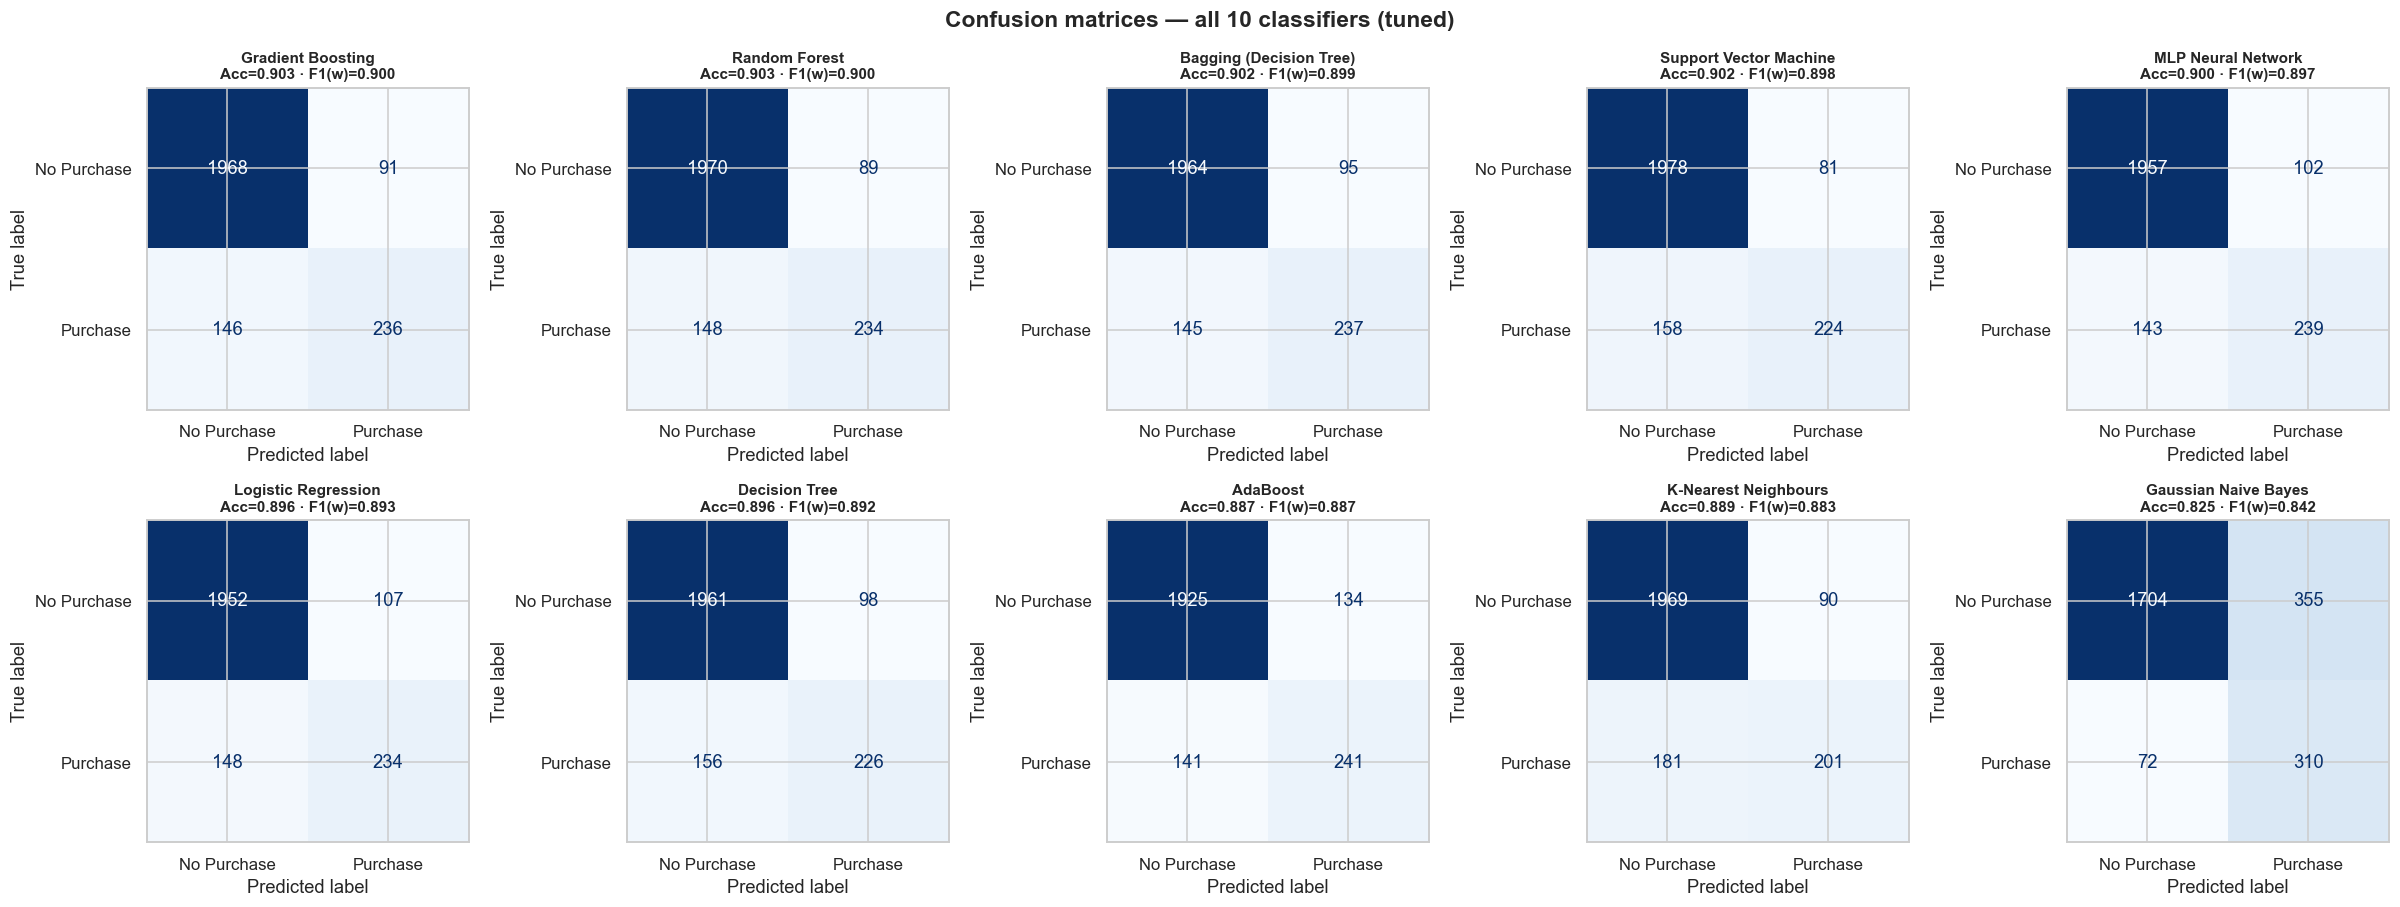

In [43]:
plot_confusion_matrices(final_table['Model'].tolist(), 'Confusion matrices — all 10 classifiers (tuned)', 'cm_all')

**📝 Observations — confusion matrices**
- Gradient Boosting catches **236 of the 382 buyers** while flagging only about 91 of the 2,059 non-buyers. The other ensembles are very similar.
- The main error for all models is **false negatives** (buyers predicted as non-buyers, 146 for Gradient Boosting). This is a natural result of the 84.5 / 15.5 imbalance at a 0.5 threshold, and §8.3 shows how moving the threshold rebalances it.
- Naive Bayes is the mirror image: few false negatives but hundreds of false positives.

### 7.3 ROC and Precision–Recall curves — all 10 models

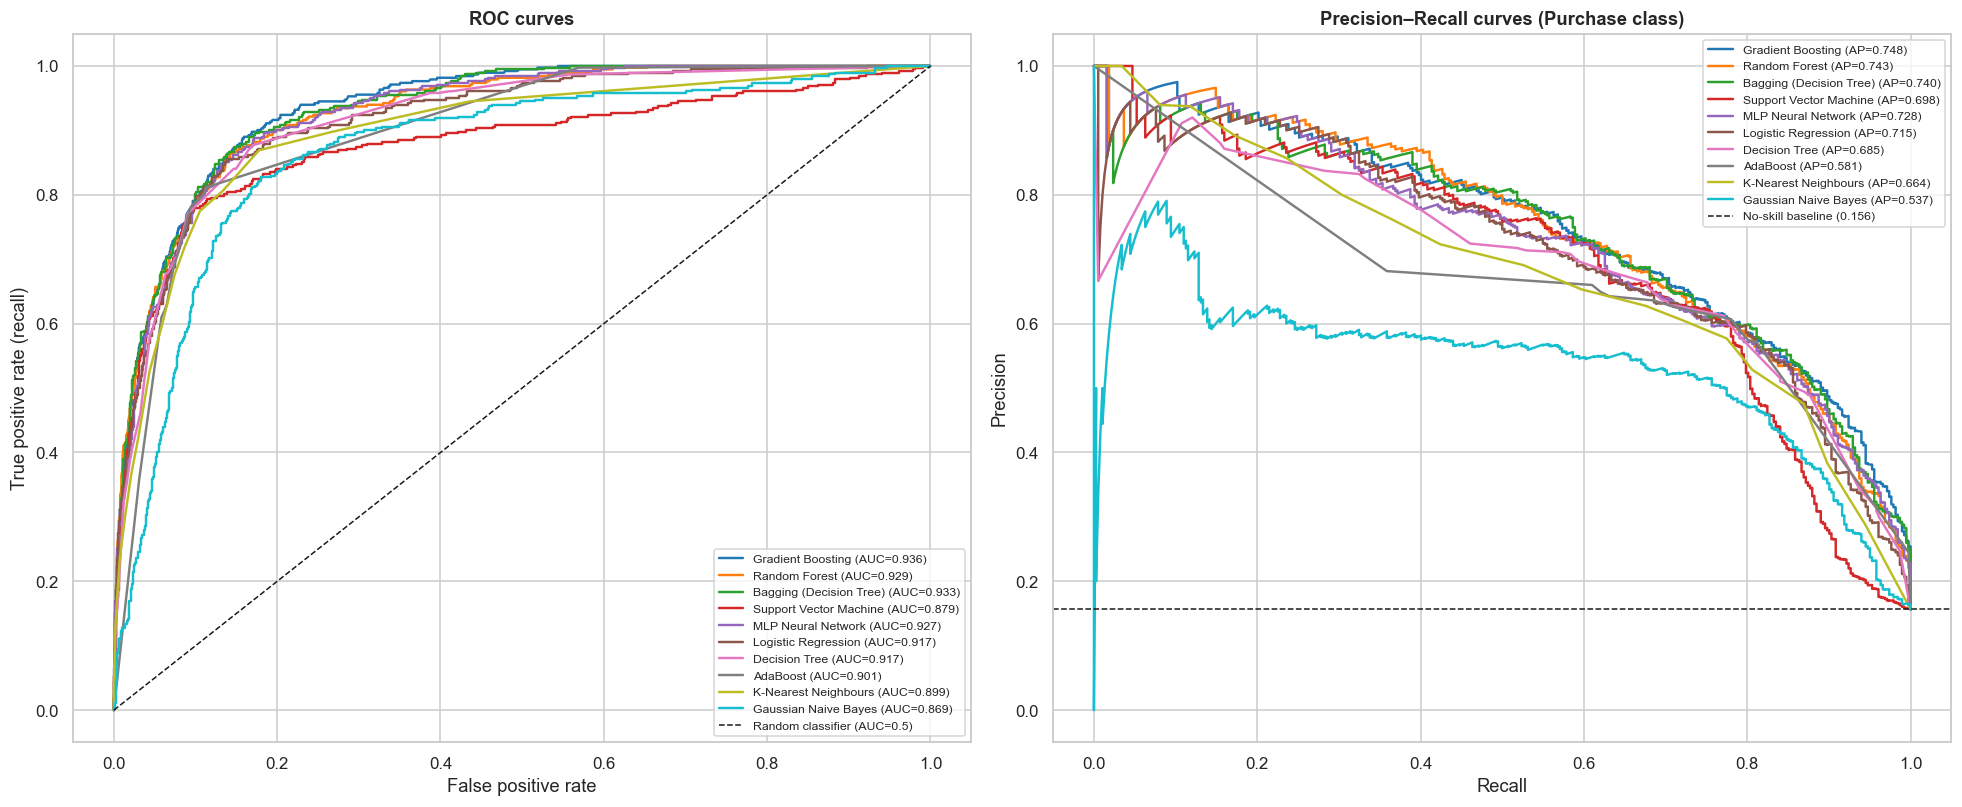

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
colors = sns.color_palette('tab10', 10)
for color, name in zip(colors, final_table['Model']):
    r = RESULTS[(name, 'Tuned')]
    fpr, tpr, _ = roc_curve(y_test, r['y_score'])
    axes[0].plot(fpr, tpr, color=color, lw=1.6, label=f"{name} (AUC={r['ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, r['y_score'])
    axes[1].plot(rec, prec, color=color, lw=1.6,
                 label=f"{name} (AP={average_precision_score(y_test, r['y_score']):.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Random classifier (AUC=0.5)')
axes[0].set(title='ROC curves', xlabel='False positive rate', ylabel='True positive rate (recall)')
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1, label=f'No-skill baseline ({y_test.mean():.3f})')
axes[1].set(title='Precision–Recall curves (Purchase class)', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.legend(fontsize=8, loc='lower right' if ax is axes[0] else 'upper right')
plt.tight_layout(); save_fig(fig, 'roc_pr_curves'); plt.show()

**📝 Observations — ROC and Precision–Recall curves**
- All ten ROC curves are far above the diagonal (AUC 0.87–0.94), so every model ranks purchasers above non-purchasers much better than chance. Gradient Boosting's curve is the highest (AUC 0.936).
- The **Precision–Recall** view is more informative for an imbalanced target: the no-skill baseline is 0.156 (the purchase rate). Gradient Boosting has the highest average precision (AP = 0.748), followed by Random Forest (0.743) and Bagging (0.740). AdaBoost (0.58) and Naive Bayes (0.54) have the lowest.
- Every PR curve falls steeply after about 0.6–0.8 recall: catching the last buyers costs a lot of precision, because those sessions look like ordinary browsing (no page value).

---
## 8 · Final model selection

**Protocol.** (1) take the two best tuned models on the test split, (2) re-check them with **5-fold stratified
cross-validation** in which the whole preprocessing pipeline is re-fitted inside every fold (no leakage), and (3)
pick the model with the best *cross-validated* weighted F1, using ROC-AUC and stability (std) as tie-breakers.

Top-2 tuned models on the test split: ['Gradient Boosting', 'Random Forest']


,Accuracy mean,Accuracy std,Precision (w) mean,Precision (w) std,Recall (w) mean,Recall (w) std,F1 (w) mean,F1 (w) std,ROC-AUC mean,ROC-AUC std
Model,,,,,,,,,,
Gradient Boosting,0.9031,0.0051,0.8976,0.0055,0.9031,0.0051,0.8989,0.0051,0.9302,0.0063
Random Forest,0.9009,0.0036,0.8954,0.0037,0.9009,0.0036,0.8969,0.0035,0.9273,0.0047


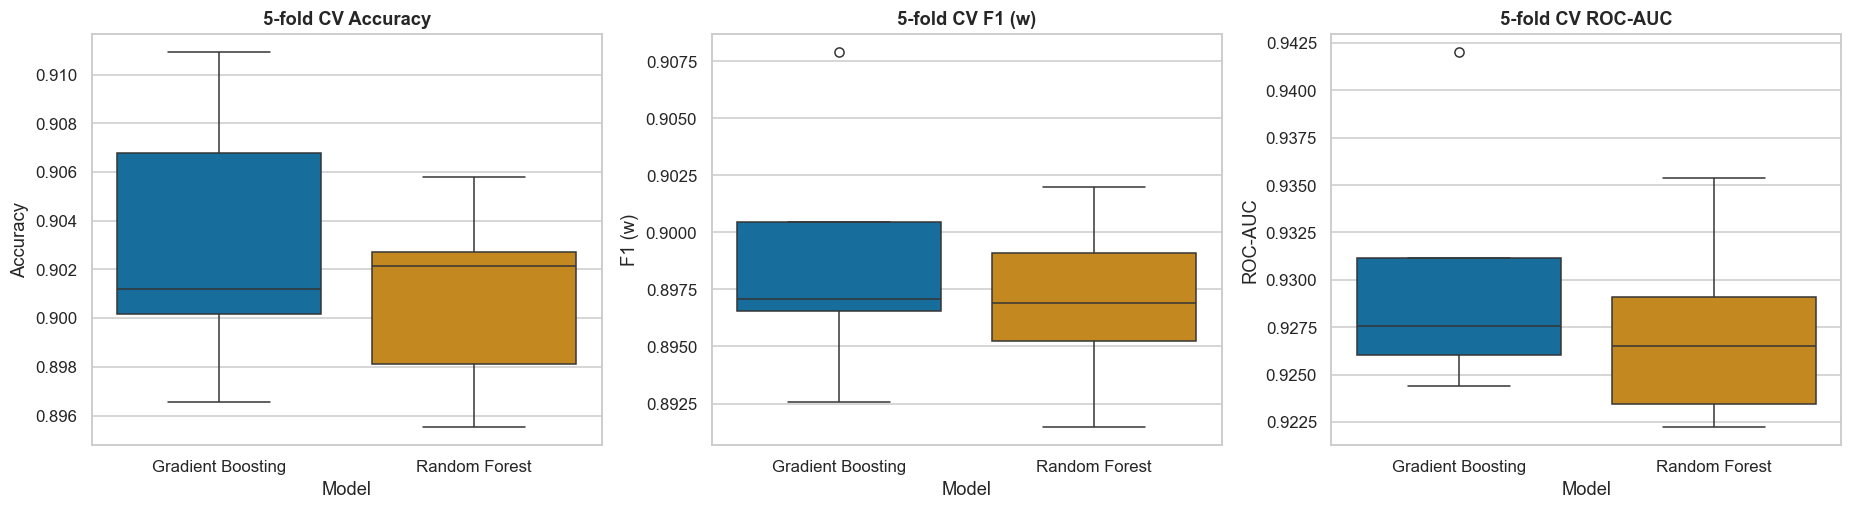


Selected final model: Gradient Boosting  (highest mean CV weighted F1)


In [45]:
top2 = final_table['Model'].head(2).tolist()
print(f'Top-2 tuned models on the test split: {top2}')

cv_rows, cv_folds = [], {}
for name in top2:
    pipe = Pipeline([('prep', build_preprocessor()), ('model', clone(RESULTS[(name, 'Tuned')]['model']))])
    cv = cross_validate(pipe, X_train, y_train, cv=CV5, n_jobs=-1,
                        scoring={'Accuracy': 'accuracy', 'F1 (w)': 'f1_weighted', 'ROC-AUC': 'roc_auc',
                                 'Precision (w)': 'precision_weighted', 'Recall (w)': 'recall_weighted'})
    cv_folds[name] = cv
    row = {'Model': name}
    for m in ['Accuracy', 'Precision (w)', 'Recall (w)', 'F1 (w)', 'ROC-AUC']:
        row[f'{m} mean'] = cv[f'test_{m}'].mean()
        row[f'{m} std'] = cv[f'test_{m}'].std()
    cv_rows.append(row)

cv_table = pd.DataFrame(cv_rows).set_index('Model')
display(cv_table.style.format('{:.4f}').set_caption('5-fold stratified CV of the top-2 models (training split)'))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, m in zip(axes, ['Accuracy', 'F1 (w)', 'ROC-AUC']):
    sns.boxplot(data=pd.DataFrame({n: cv_folds[n][f'test_{m}'] for n in top2}), ax=ax, palette='colorblind')
    ax.set(title=f'5-fold CV {m}', xlabel='Model', ylabel=m)
plt.tight_layout(); save_fig(fig, 'cv_top2'); plt.show()

BEST_NAME = cv_table['F1 (w) mean'].idxmax()
best_model = RESULTS[(BEST_NAME, 'Tuned')]['model']
print(f'\nSelected final model: {BEST_NAME}  (highest mean CV weighted F1)')

**📝 Final model selection — Gradient Boosting (tuned)**

| Criterion | Gradient Boosting | Random Forest |
|-----------|-------------------|---------------|
| Test weighted F1 | **0.8998** | 0.8995 |
| Test ROC-AUC | **0.9358** | 0.9285 |
| 5-fold CV weighted F1 (mean ± std) | **0.8989 ± 0.0051** | 0.8969 ± 0.0035 |
| 5-fold CV ROC-AUC (mean ± std) | **0.9302 ± 0.0063** | 0.9273 ± 0.0047 |
| Average precision (PR curve) | **0.748** | 0.743 |

**Justification**
1. It is best on **every** headline metric on the held-out test split **and** in 5-fold cross-validation, so the win is not an artefact of one lucky split.
2. Its test score sits inside its CV range (F1 0.8998 vs CV 0.8989 ± 0.005), so the model is **not over-fitted** to the test data.
3. It has the best ranking quality (highest ROC-AUC and average precision), which matters because the business can choose its own threshold (§8.3).
4. Random Forest is slightly more *stable* (lower std) but consistently lower, so Gradient Boosting is preferred. Both are well ahead of every single-model learner in ROC-AUC.
5. The model is compact (≈ 0.5 MB) and fast to predict, so it is suitable for the GUI.

### 8.1 Learning curve of the final model

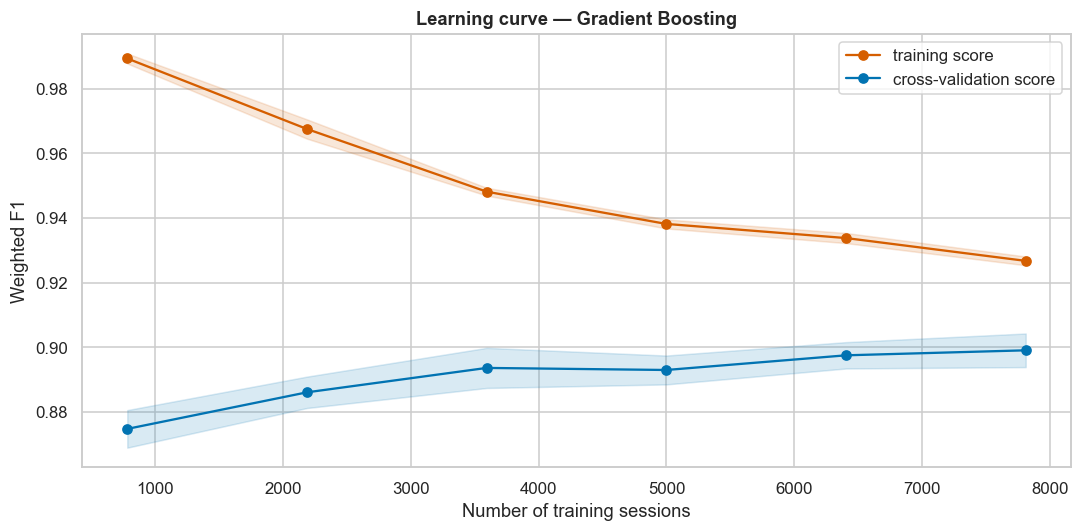

In [46]:
final_pipe = Pipeline([('prep', build_preprocessor()), ('model', clone(best_model))])
sizes, tr_scores, va_scores = learning_curve(final_pipe, X_train, y_train, cv=CV5, scoring='f1_weighted',
                                             train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)
fig, ax = plt.subplots(figsize=(10, 5))
for scores, label, color in [(tr_scores, 'training score', PALETTE[3]), (va_scores, 'cross-validation score', PALETTE[0])]:
    ax.plot(sizes, scores.mean(1), marker='o', color=color, label=label)
    ax.fill_between(sizes, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), color=color, alpha=0.15)
ax.set(title=f'Learning curve — {BEST_NAME}', xlabel='Number of training sessions', ylabel='Weighted F1')
ax.legend()
plt.tight_layout(); save_fig(fig, 'learning_curve'); plt.show()

**📝 Observations — learning curve**
- The CV score rises from about 0.875 (≈ 800 sessions) to about 0.899 (≈ 7,800 sessions), while the training score falls from 0.99 to 0.93. The two curves are converging, so the model is **not severely over-fitting** and would still gain a little from more data.
- The remaining train–CV gap (≈ 0.03 F1) is the variance cost of the boosted trees. It is moderate and stable across folds (narrow bands).

### 8.2 Which raw features drive the final model? (permutation importance on the test split)

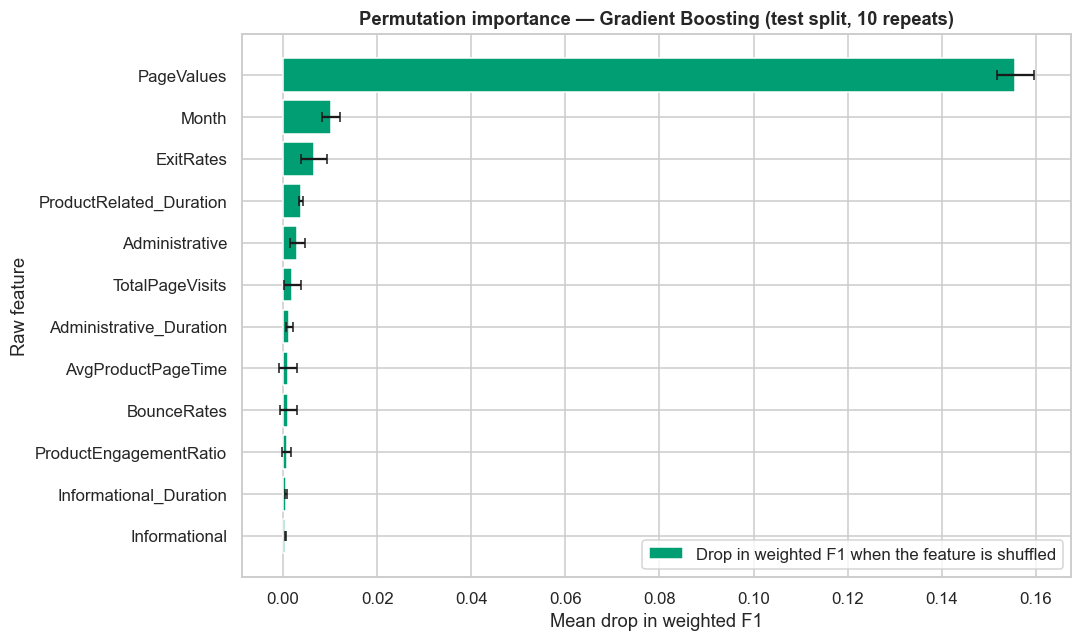

In [47]:
final_pipe = Pipeline([('prep', preprocessor), ('model', best_model)])   # already fitted on the training split
perm = permutation_importance(final_pipe, X_test, y_test, scoring='f1_weighted', n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_s = pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std},
                      index=X_test.columns).sort_values('mean').tail(12)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(perm_s.index, perm_s['mean'], xerr=perm_s['std'], color=PALETTE[2], capsize=3,
        label='Drop in weighted F1 when the feature is shuffled')
ax.set(title=f'Permutation importance — {BEST_NAME} (test split, 10 repeats)', xlabel='Mean drop in weighted F1',
       ylabel='Raw feature')
ax.legend(loc='lower right')
plt.tight_layout(); save_fig(fig, 'permutation_importance'); plt.show()

**📝 Observations — permutation importance (final model)**
- Shuffling **`PageValues`** lowers weighted F1 by about **0.155**, more than ten times any other feature. The model rests primarily on whether, and how much, the visitor reached commercially valuable pages.
- `Month` and `ExitRates` follow, then the product-page engagement features. The device, browser, region and traffic codes do not appear in the top 12.
- `HasPageValue` is not in the list because it is a copy of the information in `PageValues`: shuffling one while the other is intact costs nothing. This is a known property of permutation importance with correlated features.
- **Business reading:** focus on sessions that reach high-value pages without exiting early, especially in Q4. The visitor's technology is irrelevant.

### 8.3 Choosing a decision threshold for the business
The default 0.5 threshold optimises accuracy-like behaviour. Because only 15.5 % of sessions convert, a marketing team
may prefer to catch more buyers. We choose the threshold that maximises **Purchase-class F1 on out-of-fold
predictions of the training split** (never the test split) and then report its effect on the test split.

,Accuracy,F1 (w),Purchase Precision,Purchase Recall,Purchase F1
Threshold,,,,,
Default 0.50,0.9029,0.8998,0.7217,0.6178,0.6657
Tuned 0.31,0.8939,0.8969,0.6395,0.7382,0.6853


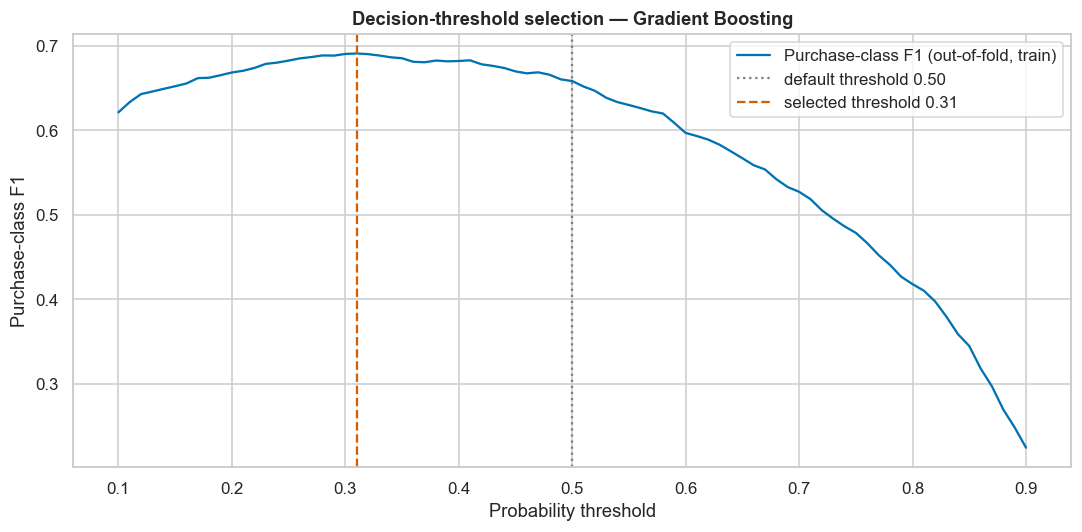

In [48]:
oof = cross_val_predict(Pipeline([('prep', build_preprocessor()), ('model', clone(best_model))]),
                        X_train, y_train, cv=CV5, method='predict_proba', n_jobs=-1)[:, 1]
thresholds = np.round(np.arange(0.10, 0.91, 0.01), 2)
f1_oof = [f1_score(y_train, (oof >= t).astype(int)) for t in thresholds]
BEST_THRESHOLD = float(thresholds[int(np.argmax(f1_oof))])

test_proba = best_model.predict_proba(X_test_p)[:, 1]
compare = []
for label, t in [('Default 0.50', 0.5), (f'Tuned {BEST_THRESHOLD:.2f}', BEST_THRESHOLD)]:
    pred = (test_proba >= t).astype(int)
    compare.append({'Threshold': label, 'Accuracy': accuracy_score(y_test, pred),
                    'F1 (w)': f1_score(y_test, pred, average='weighted'),
                    'Purchase Precision': precision_score(y_test, pred), 'Purchase Recall': recall_score(y_test, pred),
                    'Purchase F1': f1_score(y_test, pred)})
display(pd.DataFrame(compare).set_index('Threshold').style.format('{:.4f}'))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, f1_oof, color=PALETTE[0], label='Purchase-class F1 (out-of-fold, train)')
ax.axvline(0.5, color='grey', ls=':', label='default threshold 0.50')
ax.axvline(BEST_THRESHOLD, color=PALETTE[3], ls='--', label=f'selected threshold {BEST_THRESHOLD:.2f}')
ax.set(title=f'Decision-threshold selection — {BEST_NAME}', xlabel='Probability threshold', ylabel='Purchase-class F1')
ax.legend()
plt.tight_layout(); save_fig(fig, 'threshold'); plt.show()

**📝 Observations — decision threshold**
- On out-of-fold training predictions, Purchase-class F1 is maximised at a probability threshold of **0.31** instead of 0.50.
- On the untouched test split this raises **Purchase recall from 0.618 to 0.738**: about 46 more of the 382 real buyers are caught. Precision drops from 0.72 to 0.64, while weighted F1 barely changes (0.8998 → 0.8969).
- **Recommendation:** use 0.5 when false alarms are costly (e.g. sending discount codes). Use ≈ 0.31 when missing a buyer is costly (e.g. triggering a live-chat offer). The GUI shows the probability so either policy can be applied. All comparison tables in this notebook use the standard 0.5 threshold.

### 8.4 Full classification report of the final model (test split, default threshold)

In [49]:
print(classification_report(y_test, RESULTS[(BEST_NAME, 'Tuned')]['y_pred'], target_names=CLASS_NAMES, digits=4))

              precision    recall  f1-score   support

 No Purchase     0.9309    0.9558    0.9432      2059
    Purchase     0.7217    0.6178    0.6657       382

    accuracy                         0.9029      2441
   macro avg     0.8263    0.7868    0.8045      2441
weighted avg     0.8982    0.9029    0.8998      2441



---
## 9 · Saving the final model and results

The saved artefact is a single scikit-learn `Pipeline` (**preprocessor fitted on the training split + tuned model**),
so the GUI only has to call `engineer_features()` and `pipeline.predict_proba()`.

In [50]:
final_pipeline = Pipeline([('preprocessor', preprocessor), ('model', best_model)])

# Sanity check: the pipeline on RAW test rows reproduces the reported test metrics exactly
check_pred = final_pipeline.predict(X_test)
assert np.array_equal(check_pred, RESULTS[(BEST_NAME, 'Tuned')]['y_pred'])

model_path = MODELS_DIR / 'classification_best_model.pkl'
joblib.dump(final_pipeline, model_path)

best_row = final_table.set_index('Model').loc[BEST_NAME]
summary = {
    'track': 'classification',
    'dataset': 'Online Shoppers Purchasing Intention (UCI)',
    'n_rows_after_cleaning': int(len(data)), 'n_train': int(len(X_train)), 'n_test': int(len(X_test)),
    'purchase_rate': round(float(y.mean()), 4),
    'best_model': BEST_NAME,
    'best_params': (fmt_params(SEARCHES[BEST_NAME].best_params_)),
    'test_metrics': {k: round(float(best_row[k]), 4) for k in metric_cols},
    'cv_top2': {n: {k: round(float(v), 4) for k, v in r.items()} for n, r in cv_table.to_dict('index').items()},
    'decision_threshold': BEST_THRESHOLD,
    'comparison': final_table.round(4).to_dict('records'),
    'tuning_gains': gain.reset_index(names='Model').round(4).to_dict('records'),
    'input_schema': {
        'numeric_ranges': {c: [float(df[c].min()), float(df[c].max()), float(df[c].median())]
                           for c in NUM_COLS},
        'months': [m for m in MONTH_ORDER if m in df['Month'].unique()],
        'visitor_types': sorted(df['VisitorType'].unique().tolist()),
        'codes': {c: sorted(int(v) for v in df[c].unique()) for c in NOMINAL_CODES},
    },
    'random_state': RANDOM_STATE,
}
(REPORTS_DIR / 'classification_results.json').write_text(json.dumps(summary, indent=2))

# All 10 tuned models (same fitted preprocessor) — used by the GUI's model lab and live evaluation
all_models = {name: Pipeline([('preprocessor', preprocessor), ('model', RESULTS[(name, 'Tuned')]['model'])])
              for name in final_table['Model']}
joblib.dump(all_models, MODELS_DIR / 'classification_all_models.pkl', compress=3)

reloaded = joblib.load(model_path)
print(f'Saved   : {model_path.relative_to(ROOT)} ({model_path.stat().st_size / 1024:.0f} KB)')
print(f'Reloaded pipeline test weighted F1 = {f1_score(y_test, reloaded.predict(X_test), average="weighted"):.4f}')
print(f'Results : reports/classification_results.json, reports/classification_comparison.csv')
print(f'All 10 tuned pipelines: models/classification_all_models.pkl ({(MODELS_DIR / "classification_all_models.pkl").stat().st_size / 1e6:.1f} MB)')

Saved   : models\classification_best_model.pkl (492 KB)
Reloaded pipeline test weighted F1 = 0.8998
Results : reports/classification_results.json, reports/classification_comparison.csv
All 10 tuned pipelines: models/classification_all_models.pkl (4.0 MB)


---
## 10 · Conclusions

**Final model:** tuned **Gradient Boosting Classifier** (learning_rate 0.03, 200 trees, depth 4). On the 2,441-session test split it scores **accuracy 0.903, weighted F1 0.900, ROC-AUC 0.936**, with 5-fold CV weighted F1 **0.899 ± 0.005**.

**Key findings**
1. **Page value is everything.** Whether a visitor reaches pages with a Google-Analytics page value is the strongest purchase signal (56 % vs 4 % conversion). The engineered `HasPageValue` feature is the top feature for the interpretable models.
2. **Tree ensembles win.** Gradient Boosting, Random Forest and Bagging take the top three places. The relationships are threshold-like and interaction-heavy (page value × month × exit rate), which trees capture naturally.
3. **Tuning helps most where variance is high.** Decision Tree, MLP and Bagging improved the most once regularised. For LR and SVC the defaults were already optimal. Every choice was made by 5-fold CV on training data only.
4. **Imbalance changes the evaluation.** Accuracy alone would rank Naive Bayes worst and hide its high purchase recall. Weighted F1, ROC-AUC, PR curves and a tuned decision threshold give a fuller picture.

**Limitations and next steps:** data from a single year and a single shop; no user identifiers, so repeat-session behaviour cannot be modelled. Cost-sensitive learning and probability calibration would be natural next steps.

**References:** Sakar, C.O., Polat, S.O., Katircioglu, M. & Kastro, Y. (2019). *Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks.* Neural Computing and Applications 31, 6893–6908 · UCI ML Repository, dataset #468 · scikit-learn 1.8 user guide (model selection, ensemble methods).